In [1]:
!apt-get -qq install -y cd-hit > /dev/null 2>&1
!pip -q install xgboost
# MMseqs2: official release (GitHub mirror as fallback, same binary)
!which mmseqs > /dev/null 2>&1 || (wget -q https://mmseqs.com/latest/mmseqs-linux-avx2.tar.gz || wget -q https://github.com/soedinglab/MMseqs2/releases/latest/download/mmseqs-linux-avx2.tar.gz) && (which mmseqs > /dev/null 2>&1 || (tar xzf mmseqs-linux-avx2.tar.gz && cp mmseqs/bin/mmseqs /usr/local/bin/))
!mmseqs version

ae60ef6964f3de689139bcfe290d9fad18f70b06


In [3]:
# ============================ CONFIG ============================
DRIVE_DIR    = '/content/drive/MyDrive/PU-Phos4'
SPROT_RELEASE = '2026_03'   # used only if no uniprot_reldate.txt is found (the Swiss-Prot .dat file does not state its release)
OUT_NAME     = 'outputs_v4'
QUICK        = False        # True = 10-minute smoke test on a protein subset (NOT for the paper)
RESUME       = True         # reload finished runs from outputs_v4/runs (survives Colab disconnects)
ESM_SMALL    = 'facebook/esm2_t12_35M_UR50D'
ESM_LARGE    = 'facebook/esm2_t30_150M_UR50D'
RUN_LARGE    = True
WIN, SEED    = 10, 42
N_SEEDS      = 2 if QUICK else 5    # R1, R2.2: main neural models (3 in v3); use 10 for an even stronger check
N_SEEDS_AUX  = 2 if QUICK else 3    # control experiments and prior sweep
XGB_SEEDS    = 2 if QUICK else 5    # R2.2: XGBoost baselines repeated over seeds (single run in v3)
EPOCHS       = 2 if QUICK else 8
STEPS        = 60 if QUICK else 700
BATCH        = 512                  # 256 P + 256 U per step
N_BOOT       = 50 if QUICK else 2000
N_BOOT_PRIOR = 50 if QUICK else 1000  # R2.1: protein bootstrap of the class prior
PRIOR_GRID   = [0.05, 0.10, 0.15, 0.20, 0.30]
MASK_FRAC    = 0.30
TOPK         = [10, 50, 100, 500, 1000]   # R2.5: depths for candidate validation
QUICK_PROTEINS = 1500
# ================================================================
import os, re, gzip, json, time, hashlib, warnings, subprocess, platform, shutil, glob, sys
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import torch, torch.nn as nn, scipy.sparse as sp, xgboost as xgb, sklearn, scipy
from scipy import stats as sst
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupKFold
warnings.filterwarnings('ignore', category=FutureWarning)
T_START = time.time()
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
os.makedirs(DRIVE_DIR, exist_ok=True)
os.chdir(DRIVE_DIR)
OUT = os.path.join(DRIVE_DIR, OUT_NAME)
for d in ['', '/models', '/tables', '/figures', '/runs', '/external_input']: os.makedirs(OUT + d, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AA = 'ACDEFGHIKLMNPQRSTVWY'
NUM = {}                                           # every number quoted in the paper
def put(k, v): NUM[k] = v; return v
import transformers
put('versions', dict(python=platform.python_version(), torch=torch.__version__, xgboost=xgb.__version__,
                     sklearn=sklearn.__version__, scipy=scipy.__version__, transformers=transformers.__version__,
                     numpy=np.__version__, pandas=pd.__version__,
                     gpu=torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'cpu',
                     cdhit=subprocess.run('cd-hit -h | head -1', shell=True, capture_output=True, text=True).stdout.strip(),
                     mmseqs=subprocess.run('mmseqs version', shell=True, capture_output=True, text=True).stdout.strip()))
print(NUM['versions'])
# R2.6: record the exact configuration and the environment
CONFIG = {k: v for k, v in dict(OUT_NAME=OUT_NAME, QUICK=QUICK, ESM_SMALL=ESM_SMALL, ESM_LARGE=ESM_LARGE, RUN_LARGE=RUN_LARGE,
          WIN=WIN, SEED=SEED, N_SEEDS=N_SEEDS, N_SEEDS_AUX=N_SEEDS_AUX, XGB_SEEDS=XGB_SEEDS, EPOCHS=EPOCHS, STEPS=STEPS,
          BATCH=BATCH, N_BOOT=N_BOOT, N_BOOT_PRIOR=N_BOOT_PRIOR, PRIOR_GRID=PRIOR_GRID, MASK_FRAC=MASK_FRAC, TOPK=TOPK,
          QUICK_PROTEINS=QUICK_PROTEINS).items()}
json.dump(CONFIG, open(f'{OUT}/config.json', 'w'), indent=1)
open(f'{OUT}/environment.txt', 'w').write(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
# reuse the ESM-2 embeddings computed by v3 if they are still in Drive (the cache key checks that they match)
if not QUICK:
    for f_ in glob.glob(os.path.join(DRIVE_DIR, 'outputs_v3', 'esm_*.npy*')):
        dst = os.path.join(OUT, os.path.basename(f_))
        if not os.path.exists(dst): shutil.copy(f_, dst); print('reusing', os.path.basename(f_))

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'xgboost': '3.4.1', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'transformers': '5.22.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'gpu': 'Tesla T4', 'cdhit': '====== CD-HIT version 4.8.1 (built on Aug 20 2021) ======', 'mmseqs': 'ae60ef6964f3de689139bcfe290d9fad18f70b06'}


## 1. Curation with full accounting (A6, B6)

In [4]:
# v5: input setup -- the three input files must be in DRIVE_DIR. Files found elsewhere in Drive are copied here;
# a missing Swiss-Prot file is downloaded (release 2026_03 = the release used in the paper).
DRIVE_ROOT = os.path.dirname(DRIVE_DIR.rstrip('/'))
def find_in_drive(pattern):
    return sorted(f_ for f_ in glob.glob(os.path.join(DRIVE_ROOT, '**', pattern), recursive=True) if os.path.isfile(f_))
for name in ['phosphoproteins.xlsx', 'clu40.clstr']:
    if not os.path.exists(name):
        hits = find_in_drive(name) or find_in_drive(name.replace('.', '*.'))      # also e.g. 'phosphoproteins (1).xlsx'
        if hits: shutil.copy(hits[0], name); print('copied', hits[0], '->', os.path.join(DRIVE_DIR, name))
        else: raise FileNotFoundError(f'{name} is missing: upload it into {DRIVE_DIR}/ and run this cell again.')
if not any(f.startswith('uniprot_sprot') and f.endswith('.dat.gz') for f in os.listdir('.')):
    hits = [h for h in find_in_drive('uniprot_sprot*.dat.gz') if '/outputs_' not in h]
    if hits:
        shutil.copy(hits[0], 'uniprot_sprot.dat.gz'); print('copied', hits[0])
        rd_ = os.path.join(os.path.dirname(hits[0]), 'uniprot_reldate.txt')
        if os.path.exists(rd_) and not os.path.exists('uniprot_reldate.txt'): shutil.copy(rd_, 'uniprot_reldate.txt')
    else:
        url = 'https://ftp.uniprot.org/pub/databases/uniprot/previous_releases/release-2026_03/knowledgebase/uniprot_sprot-only2026_03.tar.gz'
        print('downloading Swiss-Prot release 2026_03 (about 1 GB, 5-10 min) ...')
        if subprocess.run(['wget', '-q', '-O', '/tmp/sprot.tar.gz', url]).returncode == 0:
            subprocess.run(['tar', '-xzf', '/tmp/sprot.tar.gz', '-C', '/tmp', 'uniprot_sprot.dat.gz'], check=True)
            open('uniprot_reldate.txt', 'w').write('UniProtKB/Swiss-Prot Release 2026_03 (downloaded from ' + url + ')\n')
        else:
            print('WARNING: release 2026_03 not available -> using the CURRENT release (a few labels will differ from the paper)')
            subprocess.run(['wget', '-q', '-O', '/tmp/uniprot_sprot.dat.gz', 'https://ftp.uniprot.org/pub/databases/uniprot/'
                            'current_release/knowledgebase/complete/uniprot_sprot.dat.gz'], check=True)
        shutil.copy('/tmp/uniprot_sprot.dat.gz', 'uniprot_sprot.dat.gz')
if not os.path.exists('uniprot_reldate.txt') and SPROT_RELEASE:
    open('uniprot_reldate.txt', 'w').write(f'UniProtKB/Swiss-Prot Release {SPROT_RELEASE} (set in CONFIG; check against the newest entry date below)\n')
    put('release_source', 'CONFIG')
# v5 (R2.6): record the newest entry date in the Swiss-Prot file -- identifies the release even without reldate.txt
_dt = subprocess.run("zcat uniprot_sprot.dat.gz | grep '^DT' | awk '{print $2}' | sed 's/,//' | sort -u", shell=True,
                     capture_output=True, text=True).stdout.split()
_dt = [d_ for d_ in _dt if re.fullmatch(r'\d{2}-[A-Z]{3}-\d{4}', d_)]
if _dt:
    import datetime as _d
    put('sprot_latest_entry_date', max(_d.datetime.strptime(d_.title(), '%d-%b-%Y') for d_ in _dt).strftime('%Y-%m-%d'))
    print('newest Swiss-Prot entry date in the file:', NUM['sprot_latest_entry_date'],
          '| release file:', open('uniprot_reldate.txt').read().strip() if os.path.exists('uniprot_reldate.txt') else 'none')
print('inputs in', os.getcwd(), ':', sorted(f for f in os.listdir('.') if not os.path.isdir(f)))
SPROT = next(f for f in sorted(os.listdir('.')) if f.startswith('uniprot_sprot') and f.endswith('.dat.gz'))
# R2.6: checksums of every input file, so a rerun can confirm it used the same data
def md5(path, chunk=1 << 22):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''): h.update(b)
    return h.hexdigest()
put('input_md5', {f: md5(f) for f in ['phosphoproteins.xlsx', SPROT, 'clu40.clstr'] if os.path.exists(f)})
print(NUM['input_md5'])
raw = pd.read_excel('phosphoproteins.xlsx')
CUR = [('Raw list of reviewed human phosphoproteins (sequences only)', len(raw), 'proteins')]
p = raw[~raw.Accession.str.contains('-')];                     CUR.append(('Remove isoform entries', len(p), 'proteins'))
put('n_isoform', int(raw.Accession.str.contains('-').sum()))
pe_counts = p['Protein Existence'].value_counts(dropna=False).to_dict()
p = p[(p['Protein Existence'] == 1) | p['Protein Existence'].isna()]; CUR.append(('Remove protein-existence levels 2, 3 and 5', len(p), 'proteins'))
put('pe_counts', {str(k): int(v) for k, v in pe_counts.items()})
prot = p.drop_duplicates('Sequence').reset_index(drop=True);   CUR.append(('Remove duplicate sequences', len(prot), 'proteins'))
if QUICK:   # smoke test only
    prot = prot.sample(min(QUICK_PROTEINS, len(prot)), random_state=0).reset_index(drop=True)
    print(f'QUICK mode: using {len(prot)} proteins')
for c in CUR: print(c)
print('protein-existence levels before filtering:', pe_counts)

copied /content/drive/MyDrive/PU-Phos3/phosphoproteins.xlsx -> /content/drive/MyDrive/PU-Phos4/phosphoproteins.xlsx
copied /content/drive/MyDrive/PU-Phos3/clu40.clstr -> /content/drive/MyDrive/PU-Phos4/clu40.clstr
copied /content/drive/MyDrive/PU-Phos3/uniprot_sprot.dat.gz
newest Swiss-Prot entry date in the file: 2026-09-02 | release file: UniProtKB/Swiss-Prot Release 2026_03 (set in CONFIG; check against the newest entry date below)
inputs in /content/drive/MyDrive/PU-Phos4 : ['clu40.clstr', 'phosphoproteins.xlsx', 'uniprot_reldate.txt', 'uniprot_sprot.dat.gz']
{'phosphoproteins.xlsx': '75d44a89626d70ab879fdb1d9f74858a', 'uniprot_sprot.dat.gz': 'a31b5d0756f0a8f94164bf20b703812c', 'clu40.clstr': 'adcd345aadcd30273987daf02c16e1bb'}
('Raw list of reviewed human phosphoproteins (sequences only)', 8591, 'proteins')
('Remove isoform entries', 8383, 'proteins')
('Remove protein-existence levels 2, 3 and 5', 8354, 'proteins')
('Remove duplicate sequences', 8348, 'proteins')
protein-existence

In [5]:
def parse_modres(path, accessions):
    rows, acc, human, ft, field = [], None, False, None, None
    def flush():
        if ft and human and acc in accessions: rows.append(tuple(ft))
    with gzip.open(path, 'rt') as f:
        for line in f:
            tag = line[:2]
            if tag == 'ID': acc, human, ft = None, False, None
            elif tag == 'AC' and acc is None: acc = line[5:].split(';')[0].strip()
            elif tag == 'OX': human = 'NCBI_TaxID=9606' in line
            elif tag == 'FT':
                key, body = line[5:21].strip(), line[21:].strip()
                if key == 'MOD_RES':
                    flush(); ft = [acc, body, '', '']; field = None
                elif key == '' and ft:
                    m = re.match(r'/(note|evidence)="(.*)', body)
                    if m:
                        field = 2 if m.group(1) == 'note' else 3
                        ft[field] = m.group(2).rstrip('"')
                    elif field is not None:
                        ft[field] += ' ' + body.rstrip('"')
                else:
                    flush(); ft = None
            elif tag == '//': flush(); ft = None
    return pd.DataFrame(rows, columns=['accession', 'pos', 'note', 'evidence'])

_rt = open('uniprot_reldate.txt').read() if os.path.exists('uniprot_reldate.txt') else ''
rel = (re.search(r'Release (\d{4}_\d{2})', _rt) or [None, 'unknown'])[1]
sites = parse_modres(SPROT, set(prot.Accession))
sites = sites[sites.note.str.startswith('Phospho')]
n_pos_nonnum = int((~sites.pos.str.fullmatch(r'\d+')).sum())
sites = sites[sites.pos.str.fullmatch(r'\d+')].astype({'pos': int})
def evidence_label(ev):
    if 'ECO:0000269' in ev or 'ECO:0007744' in ev: return 'P'
    if 'ECO:0000250' in ev: return 'H'
    return 'X'
sites['label'] = sites.evidence.map(evidence_label)
n_rows = len(sites)
# resolve several annotations of the same residue by evidence priority P > H > X
sites['prio'] = sites.label.map({'P': 0, 'H': 1, 'X': 2})
uniq = sites.sort_values('prio').drop_duplicates(['accession', 'pos'])
seq_of = dict(zip(prot.Accession, prot.Sequence))
on_sty = uniq.apply(lambda r: r.pos <= len(seq_of[r.accession]) and seq_of[r.accession][r.pos - 1] in 'STY', axis=1)
ACC = dict(annotation_rows=n_rows, duplicate_rows_same_residue=n_rows - len(uniq), unique_residues=len(uniq),
           not_on_STY=int((~on_sty).sum()), mapped=int(on_sty.sum()), non_numeric_positions=n_pos_nonnum)
ACC.update({f'mapped_{k}': int(v) for k, v in uniq[on_sty].label.value_counts().items()})
put('site_accounting', ACC); put('release', rel)
print(json.dumps(ACC, indent=1))
sites = uniq[on_sty]
site_label = {(a, p_): l for a, p_, l in sites[['accession', 'pos', 'label']].itertuples(index=False)}
sites.drop(columns='prio').to_csv(f'{OUT}/uniprot_phosphosites_mapped.csv', index=False)

{
 "annotation_rows": 40834,
 "duplicate_rows_same_residue": 12,
 "unique_residues": 40822,
 "not_on_STY": 28,
 "mapped": 40794,
 "non_numeric_positions": 590,
 "mapped_P": 30492,
 "mapped_H": 9870,
 "mapped_X": 432
}


## 2. Split (CD-HIT 40%) and test-vs-train homology check with MMseqs2 (A7)

In [6]:
cluster, cid = {}, -1
for line in open('clu40.clstr'):
    if line.startswith('>Cluster'): cid += 1
    else: cluster[re.search(r'>(\S+?)\.\.\.', line).group(1)] = cid
prot['cluster'] = prot.Accession.map(cluster)
assert prot.cluster.notna().all()
ids = np.random.default_rng(SEED).permutation(np.sort(prot.cluster.unique())); n = len(ids)
split_of = {c: 'train' for c in ids[:int(.7*n)]}
split_of.update({c: 'val' for c in ids[int(.7*n):int(.8*n)]})
split_of.update({c: 'test' for c in ids[int(.8*n):]})
prot['split'] = prot.cluster.map(split_of)
put('n_clusters', int(n)); put('proteins_per_split', prot.split.value_counts().to_dict())

os.makedirs('/content/mm', exist_ok=True)
for s in ['train', 'test']:
    with open(f'/content/mm/{s}.fa', 'w') as f:
        for a, q in zip(prot[prot.split == s].Accession, prot[prot.split == s].Sequence): f.write(f'>{a}\n{q}\n')
!cd /content/mm && mmseqs easy-search test.fa train.fa hits.m8 tmp -s 7.5 -e 1e-3 --format-output "query,target,fident,alnlen,qlen,tlen,evalue,bits,qcov,tcov" > mm.log 2>&1
if not os.path.exists('/content/mm/hits.m8'):   # v5: MMseqs2 missing (install cell not run in this session) -> install and retry
    !(wget -q -O /tmp/mm.tgz https://mmseqs.com/latest/mmseqs-linux-avx2.tar.gz || wget -q -O /tmp/mm.tgz https://github.com/soedinglab/MMseqs2/releases/latest/download/mmseqs-linux-avx2.tar.gz) && tar xzf /tmp/mm.tgz -C /tmp && cp /tmp/mmseqs/bin/mmseqs /usr/local/bin/
    !cd /content/mm && mmseqs easy-search test.fa train.fa hits.m8 tmp -s 7.5 -e 1e-3 --format-output "query,target,fident,alnlen,qlen,tlen,evalue,bits,qcov,tcov" > mm.log 2>&1
if not os.path.exists('/content/mm/hits.m8'): raise RuntimeError('MMseqs2 failed:\n' + open('/content/mm/mm.log').read()[-2000:])
hits = pd.read_csv('/content/mm/hits.m8', sep='\t', header=None, names='q t fident alnlen qlen tlen evalue bits qcov tcov'.split())
sig = hits[(hits.fident >= 0.40) & (hits.qcov >= 0.50)]
leaky = set(sig.q)
prot['strict_test'] = (prot.split == 'test') & ~prot.Accession.isin(leaky)
H = dict(test_proteins=int((prot.split == 'test').sum()), with_any_hit=int(hits.q.nunique()),
         max_identity=float(hits.fident.max()) if len(hits) else 0.0,
         over40_cov50=len(leaky), over50_cov50=int(hits[(hits.fident >= .5) & (hits.qcov >= .5)].q.nunique()),
         over70_cov50=int(hits[(hits.fident >= .7) & (hits.qcov >= .5)].q.nunique()),
         strict_test_proteins=int(prot.strict_test.sum()))
put('homology', H); print(H)
prot[['Accession', 'cluster', 'split', 'strict_test']].to_csv(f'{OUT}/protein_split.csv', index=False)

{'test_proteins': 1679, 'with_any_hit': 1062, 'max_identity': 1.0, 'over40_cov50': 245, 'over50_cov50': 76, 'over70_cov50': 10, 'strict_test_proteins': 1434}


### Export of the test proteins for established predictors (R1, R2.4)

In [7]:
# R1, R2.4: export the test proteins so established predictors (e.g. NetPhos, MusiteDeep, LMPhosSite web servers
# or local installations) can be run on exactly the same proteins. Put their predictions in DRIVE_DIR/external/
# as <ToolName>.csv with columns accession, position, score (see Section 11).
def write_fasta(df, path):
    with open(path, 'w') as f:
        for a, q in zip(df.Accession, df.Sequence):
            f.write(f'>{a}\n' + '\n'.join(q[i:i + 60] for i in range(0, len(q), 60)) + '\n')
tp_ = prot[prot.split == 'test']; sp_ = prot[prot.strict_test]
write_fasta(tp_, f'{OUT}/external_input/test_proteins.fasta')
write_fasta(sp_, f'{OUT}/external_input/strict_test_proteins.fasta')
CHUNK = 200                                    # many web servers limit the number of sequences per job
for i in range(0, len(sp_), CHUNK):
    write_fasta(sp_.iloc[i:i + CHUNK], f'{OUT}/external_input/strict_test_part{i // CHUNK + 1:02d}.fasta')
print(f'FASTA written: {len(tp_)} test and {len(sp_)} strict-test proteins '
      f'({(len(sp_) + CHUNK - 1) // CHUNK} chunks of <= {CHUNK}) in {OUT}/external_input/')

FASTA written: 1679 test and 1434 strict-test proteins (8 chunks of <= 200) in /content/drive/MyDrive/PU-Phos4/outputs_v4/external_input/


## 3. Residue-level dataset, statistics and label sanity checks (B7)

In [8]:
rows = []
strict = dict(zip(prot.Accession, prot.strict_test))
for acc, seq, split in zip(prot.Accession, prot.Sequence, prot.split):
    padded = '-' * WIN + seq + '-' * WIN
    for i, aa in enumerate(seq):
        if aa in 'STY':
            rows.append((acc, i + 1, aa, padded[i:i + 2*WIN + 1], site_label.get((acc, i + 1), 'U'), split, strict[acc]))
ds = pd.DataFrame(rows, columns=['accession', 'pos', 'res', 'window', 'label', 'split', 'strict_test'])
ds.to_csv(f'{OUT}/PU-Phos_dataset.csv.gz', index=False)
CUR += [('Map phosphosite annotations onto S/T/Y residues', len(sites), 'sites'),
        ('Enumerate all S/T/Y residues (21-residue windows)', len(ds), 'residues'),
        ('Exclude weak-evidence sites (X) from modelling', int((ds.label != 'X').sum()), 'residues')]
put('curation', CUR)
tab = pd.crosstab(ds.label, ds.split).reindex(index=['P', 'H', 'U', 'X'], columns=['train', 'val', 'test'])
tab['strict test'] = ds[ds.strict_test].label.value_counts().reindex(tab.index).fillna(0).astype(int)
put('dataset_table', tab.to_dict()); put('pos_by_res', ds[ds.label == 'P'].res.value_counts().to_dict())
put('h_by_res', ds[ds.label == 'H'].res.value_counts().to_dict())
put('n_sty', len(ds)); put('n_model', int((ds.label != 'X').sum()))
display(tab)

def freq(w):
    M = np.zeros((20, 2*WIN+1))
    for s in w:
        for j, c in enumerate(s):
            if c in AA: M[AA.index(c), j] += 1
    return M / M.sum(0, keepdims=True)
PSEUDO = 1e-4
def enrich(lab, res=None, n_u=100000):
    m = (ds.label == lab) if res is None else (ds.label == lab) & (ds.res == res)
    mu = (ds.label == 'U') if res is None else (ds.label == 'U') & (ds.res == res)
    return np.log2((freq(ds.window[m]) + PSEUDO) / (freq(ds.window[mu].sample(min(n_u, mu.sum()), random_state=0)) + PSEUDO))
eP, eH = enrich('P'), enrich('H')
keep_cols = [j for j in range(2*WIN+1) if j != WIN]
r_PH = float(np.corrcoef(eP[:, keep_cols].ravel(), eH[:, keep_cols].ravel())[0, 1])
put('motif_corr_P_H', r_PH); print('Pearson r between P-vs-U and H-vs-U motif profiles:', round(r_PH, 3))

split,train,val,test,strict test
label,,,,
P,21555,2778,6159,5362
H,6983,844,2043,1677
U,663178,99211,189511,163405
X,316,45,71,58


Pearson r between P-vs-U and H-vs-U motif profiles: 0.917


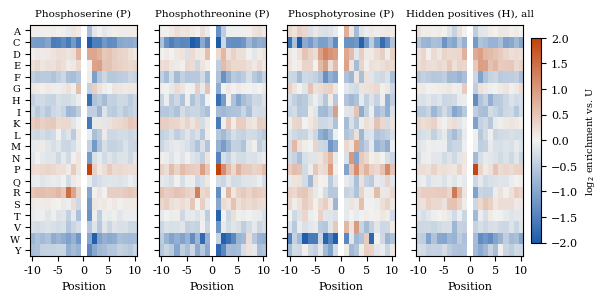

In [9]:
from matplotlib.colors import LinearSegmentedColormap
plt.rcParams.update({'font.family': 'serif', 'font.size': 8, 'pdf.fonttype': 42})
cmap = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#f2f2f0', '#c2410c'])
fig, axs = plt.subplots(1, 4, figsize=(6.6, 3.0), sharey=True)
panels = [('P', 'S', 'Phosphoserine (P)'), ('P', 'T', 'Phosphothreonine (P)'), ('P', 'Y', 'Phosphotyrosine (P)'), ('H', None, 'Hidden positives (H), all')]
for ax, (lab, res, title) in zip(axs, panels):
    e = enrich(lab, res); e = np.clip(e, -2, 2); e[:, WIN] = np.nan
    im = ax.imshow(np.ma.masked_invalid(e), cmap=cmap, vmin=-2, vmax=2, aspect='auto')
    ax.set_title(title, fontsize=7.5); ax.set_xticks([0, 5, 10, 15, 20]); ax.set_xticklabels([-10, -5, 0, 5, 10])
    ax.set_xlabel('Position')
axs[0].set_yticks(range(20)); axs[0].set_yticklabels(list(AA), fontsize=7)
cb = fig.colorbar(im, ax=axs, fraction=.02, pad=.015); cb.set_label('log$_2$ enrichment vs. U', fontsize=7)
plt.savefig(f'{OUT}/figures/fig_motif.pdf', bbox_inches='tight'); plt.show()

## 4. Setup, evaluation and seed-paired bootstrap (A1, C1–C6)



In [10]:
data = ds[ds.label != 'X'].reset_index(drop=True)
KEEP = np.where(ds.label.values != 'X')[0]
IDX = {a: i + 1 for i, a in enumerate(AA)}
X = np.array([[IDX.get(c, 0) for c in w] for w in data.window], dtype=np.int64)
L, S, R = data.label.values, data.split.values, data.res.values
tr, va, te = S == 'train', S == 'val', S == 'test'
ts = te & data.strict_test.values
y_all = (L == 'P').astype(np.int64)                       # main models: ALL training positives
rng = np.random.default_rng(0)
tr_pos = np.where(tr & (L == 'P'))[0]
masked = rng.choice(tr_pos, int(MASK_FRAC * len(tr_pos)), replace=False)   # only for the causal controls
put('n_train_pos', int(len(tr_pos))); put('n_masked', int(len(masked)))
prot_idx = pd.factorize(data.accession)[0]

def metrics(score, sub):
    r = {}
    m = sub & np.isin(L, ['P', 'U'])
    r['AUC'] = roc_auc_score(L[m] == 'P', score[m]); r['AUPRC'] = average_precision_score(L[m] == 'P', score[m])
    m = sub & np.isin(L, ['H', 'U'])
    r['HP_AUC'] = roc_auc_score(L[m] == 'H', score[m]); r['HP_AUPRC'] = average_precision_score(L[m] == 'H', score[m])
    for aa in 'STY':
        m = sub & np.isin(L, ['P', 'U']) & (R == aa)
        r[f'AUC_{aa}'] = roc_auc_score(L[m] == 'P', score[m]); r[f'AUPRC_{aa}'] = average_precision_score(L[m] == 'P', score[m])
        m = sub & np.isin(L, ['H', 'U']) & (R == aa)
        r[f'HP_AUC_{aa}'] = roc_auc_score(L[m] == 'H', score[m]) if (L[m] == 'H').sum() > 0 else np.nan
    return {k: float(v) for k, v in r.items()}

RES, SC, CURVES = [], {}, []            # SC[(model, ckpt)] = list of per-seed score arrays (float32)
def record(model, ckpt, seed, score, **extra):
    score = score.astype(np.float32)
    SC.setdefault((model, ckpt), []).append(score)
    for subname, sub in [('test', te), ('strict', ts)]:
        RES.append(dict(model=model, ckpt=ckpt, seed=seed, subset=subname, **extra, **metrics(score, sub)))
    r = [x for x in RES if x['model'] == model and x['ckpt'] == ckpt and x['seed'] == seed and x['subset'] == 'test'][-1]
    print(f"{model:24s} {ckpt:5s} seed {seed}: AUC {r['AUC']:.4f} AUPRC {r['AUPRC']:.4f} HP {r['HP_AUC']:.4f}")

# R2.6: every run's scores are cached, so an interrupted Colab session resumes where it stopped
def cache_path(tag, seed, extra=''):
    key = hashlib.md5(f'{tag}|{seed}|{EPOCHS}|{STEPS}|{BATCH}|{QUICK}|{extra}|{len(data)}'.encode()).hexdigest()[:10]
    return f'{OUT}/runs/{tag}_seed{seed}_{key}.npz'

def wauc(order_y, order_w):
    neg = np.cumsum(order_w * (~order_y)); pos_w = order_w * order_y
    return (pos_w * neg).sum() / (pos_w.sum() * (order_w * (~order_y)).sum())

def paired_stats(A, B, pos='P', sub=None, n=N_BOOT):
    """AUC(A) - AUC(B) for positives `pos` vs U.
    point     : mean over seeds of the per-seed difference (seed s of A paired with seed s of B)
    lo, hi, p : protein-level bootstrap (as in v3)
    h_lo, h_hi, h_p : two-level bootstrap -- seeds AND proteins resampled (R1, R2.2)
    seed_diffs, n_A_better : per-seed differences and how many favour A
    A model with a single deterministic run (e.g. PSSM) is reused for every seed of the other model."""
    sub = te if sub is None else sub
    m = sub & np.isin(L, [pos, 'U']); y = (L[m] == pos); pidx = prot_idx[m]
    up, inv = np.unique(pidx, return_inverse=True)
    sa, sb = SC[A], SC[B]
    k = max(len(sa), len(sb)) if min(len(sa), len(sb)) == 1 else min(len(sa), len(sb))
    ia = [s % len(sa) for s in range(k)]; ib = [s % len(sb) for s in range(k)]
    oa = [np.argsort(sa[i][m], kind='mergesort') for i in ia]
    ob = [np.argsort(sb[i][m], kind='mergesort') for i in ib]
    seed_d = np.array([roc_auc_score(y, sa[i][m]) - roc_auc_score(y, sb[j][m]) for i, j in zip(ia, ib)])
    g = np.random.default_rng(1); g2 = np.random.default_rng(2); d = np.empty(n); dh = np.empty(n)   # g = same stream as v3
    for b in range(n):
        w = np.bincount(g.integers(0, len(up), len(up)), minlength=len(up))[inv].astype(np.float64)
        dv = np.array([wauc(y[oa[s]], w[oa[s]]) - wauc(y[ob[s]], w[ob[s]]) for s in range(k)])
        d[b] = dv.mean(); dh[b] = dv[g2.integers(0, k, k)].mean()
    pval = lambda x: float(max(2 * min((x <= 0).mean(), (x >= 0).mean()), 1 / n))
    lo, hi = np.percentile(d, [2.5, 97.5]); hlo, hhi = np.percentile(dh, [2.5, 97.5])
    return dict(point=float(seed_d.mean()), lo=float(lo), hi=float(hi), p=pval(d), h_lo=float(hlo), h_hi=float(hhi), h_p=pval(dh),
                seed_diffs=[float(x) for x in seed_d], n_A_better=int((seed_d > 0).sum()), k=int(k))

def boot_diff(A, B, pos='P', sub=None, n=N_BOOT):
    s = paired_stats(A, B, pos, sub, n); return s['point'], s['lo'], s['hi']

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); adj = np.empty_like(p); run_max = 0.0
    for r, i in enumerate(order):
        run_max = max(run_max, min(1.0, (len(p) - r) * p[i])); adj[i] = run_max
    return adj

# sanity: weighted AUC with unit weights equals sklearn
_m = te & np.isin(L, ['P', 'U']); _s = np.random.default_rng(0).random(len(L))
_o = np.argsort(_s[_m]); print('wauc check:', round(wauc((L[_m] == 'P')[_o], np.ones(_m.sum())), 6), round(roc_auc_score(L[_m] == 'P', _s[_m]), 6))
print('holm check:', holm([0.01, 0.04, 0.03, 0.2]))

wauc check: 0.497781 0.497781
holm check: [0.04 0.09 0.09 0.2 ]


## 5. Class prior by 5-fold cross-fitting on training proteins (B3–B5), and XGBoost baselines (B8)


In [11]:
def onehot(Xi):
    r = np.repeat(np.arange(len(Xi)), Xi.shape[1]); c = (np.arange(Xi.shape[1]) * 21)[None, :] + Xi
    return sp.csr_matrix((np.ones(r.size, np.float32), (r, c.ravel())), shape=(len(Xi), 21 * Xi.shape[1]))
OH = onehot(X)
xp = dict(n_estimators=100 if QUICK else 300, max_depth=6, learning_rate=.1, subsample=.8, colsample_bytree=.5,
          tree_method='hist', n_jobs=-1, random_state=SEED)
if DEVICE == 'cuda': xp['device'] = 'cuda'
trI = np.where(tr)[0]

# ---- class prior: Elkan & Noto with 5-fold cross-fitting on training proteins (unweighted classifier) ----
oof = np.zeros(len(trI))
for f_tr, f_te in GroupKFold(5).split(trI, groups=prot_idx[trI]):
    g = xgb.XGBClassifier(**xp).fit(OH[trI[f_tr]], y_all[trI[f_tr]])
    oof[f_te] = g.predict_proba(OH[trI[f_te]])[:, 1]
yl = y_all[trI]
def prior_from(lam_, c_):
    pi_ = min(lam_ / c_, .5); return pi_, pi_ * (1 - c_) / (1 - c_ * pi_)
lam = float(yl.mean()); c = float(oof[yl == 1].mean()); pi, PI_U = prior_from(lam, c)
pd.DataFrame({'accession': data.accession.values[trI], 'pos': data.pos.values[trI], 'labelled': yl, 'oof_score': oof}) \
  .to_csv(f'{OUT}/prior_oof_scores.csv.gz', index=False)                       # R2.6

# R2.1 (a): uncertainty of the prior -- bootstrap over training proteins (out-of-fold scores held fixed)
up_, inv_ = np.unique(prot_idx[trI], return_inverse=True)
n_p = np.bincount(inv_).astype(float); n_lab = np.bincount(inv_, weights=yl.astype(float)); s_lab = np.bincount(inv_, weights=oof * yl)
g_ = np.random.default_rng(7); BS = []
for b in range(N_BOOT_PRIOR):
    w = np.bincount(g_.integers(0, len(up_), len(up_)), minlength=len(up_))
    lam_b = (w * n_lab).sum() / (w * n_p).sum(); c_b = (w * s_lab).sum() / (w * n_lab).sum()
    BS.append((lam_b, c_b) + prior_from(lam_b, c_b))
BS = np.array(BS); ci = lambda j: [float(x) for x in np.percentile(BS[:, j], [2.5, 97.5])]
# R2.1 (b): sensitivity to the estimator -- Elkan & Noto e1 (used), e2, and a robust e3 (99.9th percentile instead of max)
alt = {}
for nm, c_ in [('e1', c), ('e2', float(oof[yl == 1].sum() / oof.sum())), ('e3', float(np.quantile(oof, 0.999)))]:
    p1, p2 = prior_from(lam, c_); alt[nm] = dict(c=float(c_), pi=float(p1), pi_U=float(p2))
# R2.1 (c): SCAR diagnostic -- if labels were selected completely at random with one prior, the number of labelled
# sites per protein would be close to binomial. Over-dispersion means some proteins are labelled far more than others.
exp_ = n_p * lam
disp = float((((n_lab - exp_) ** 2) / (n_p * lam * (1 - lam))).sum() / (len(n_p) - 1))
put('prior', dict(labelled_fraction=lam, c=c, pi_all=pi, pi_U=PI_U, implied_sites=int(round(pi * len(ds))), n_sty_total=len(ds),
                  lam_ci=ci(0), c_ci=ci(1), pi_ci=ci(2), pi_U_ci=ci(3), alt_estimators=alt))
put('scar_diag', dict(dispersion_index=disp, proteins_without_P=float((n_lab == 0).mean()),
                      expected_without_P_if_binomial=float(np.mean((1 - lam) ** n_p)),
                      top10pct_proteins_share_of_P=float(np.sort(n_lab)[::-1][:max(1, len(n_lab) // 10)].sum() / n_lab.sum())))
PI_U_CI = NUM['prior']['pi_U_ci']
print(json.dumps(NUM['prior'], indent=1)); print(NUM['scar_diag'])

# ---- XGBoost baselines, now over XGB_SEEDS seeds (R1, R2.2) ----
spw = float((yl == 0).sum() / (yl == 1).sum()); put('xgb_scale_pos_weight', spw)
P_ = np.where(tr & (y_all == 1))[0]; U_ = np.where(tr & (y_all == 0))[0]; K = 3 if QUICK else 10
for s_ in range(XGB_SEEDS):
    cp = cache_path('XGB', s_, f'{K}')
    if RESUME and os.path.exists(cp):
        z = np.load(cp); pn_sc, bag = z['pn'], z['bag']
    else:
        # seed 0 is exactly the v3 run (random_state=SEED, bags drawn with the same generator `rng`);
        # seeds 1.. are the extra repeats asked for by the reviewers
        xs = dict(xp, random_state=SEED + s_)
        pn_sc = xgb.XGBClassifier(**xs, scale_pos_weight=spw).fit(OH[trI], yl).predict_proba(OH)[:, 1]
        # balanced bagging (Mordelet & Vert's PU-bagging): each bag = all P + an equal-size random subset of U
        gb = rng if s_ == 0 else np.random.default_rng(100 + s_); bag = np.zeros(len(data))
        for k in range(K):
            ub = gb.choice(U_, len(P_), replace=False)
            mk = xgb.XGBClassifier(**(xs if s_ == 0 else dict(xs, random_state=SEED + 100 * s_ + k))).fit(OH[np.r_[P_, ub]], np.r_[np.ones(len(P_)), np.zeros(len(ub))])
            bag += mk.predict_proba(OH)[:, 1] / K
        np.savez(cp, pn=pn_sc.astype(np.float32), bag=bag.astype(np.float32))
    record('PN-XGB', '-', s_, pn_sc); record('Bag-XGB', '-', s_, bag)
put('bag_U_coverage', float(K * len(P_) / len(U_)))

# ---- R1, R2.4: a classic established-style baseline -- position-specific log-odds motif score (PSSM),
#      as used by early motif scanners; deterministic, trained on training windows only ----
def counts(Z): return np.stack([np.bincount(Z[:, j], minlength=21) for j in range(Z.shape[1])], 1) + 1.0   # Laplace
cP, cU = counts(X[tr & (y_all == 1)]), counts(X[tr & (y_all == 0)])
LO = np.log(cP / cP.sum(0)) - np.log(cU / cU.sum(0))
record('PSSM', '-', 0, LO[X, np.arange(X.shape[1])].sum(1))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [14:32:47] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


{
 "labelled_fraction": 0.03116163280884062,
 "c": 0.14533942624008908,
 "pi_all": 0.21440591596504655,
 "pi_U": 0.18913813631004808,
 "implied_sites": 212839,
 "n_sty_total": 992694,
 "lam_ci": [
  0.029628627767644786,
  0.032652789123669444
 ],
 "c_ci": [
  0.1423116046007236,
  0.1482453246167356
 ],
 "pi_ci": [
  0.20284220753451074,
  0.2256402678484111
 ],
 "pi_U_ci": [
  0.17847004634292518,
  0.1995306886689775
 ],
 "alt_estimators": {
  "e1": {
   "c": 0.14533942624008908,
   "pi": 0.21440591596504655,
   "pi_U": 0.18913813631004808
  },
  "e2": {
   "c": 0.147097621601453,
   "pi": 0.21184321316404486,
   "pi_U": 0.1864930069594925
  },
  "e3": {
   "c": 0.5614136719703702,
   "pi": 0.05550565361095311,
   "pi_U": 0.02512701976562952
  }
 }
}
{'dispersion_index': 7.588412804168897, 'proteins_without_P': 0.2205681040383299, 'expected_without_P_if_binomial': 0.12895576125544336, 'top10pct_proteins_share_of_P': 0.4657852006495013}
PN-XGB                   -     seed 0: AUC 0.86

## 6. Neural training (epoch = 700 steps × (256 P + 256 U), sampled with replacement)



In [12]:
class WindowCNN(nn.Module):
    # embedding(21->24) -> Conv1d(24->96,k7) -> ReLU -> Conv1d(96->96,k5) -> ReLU (stacked);
    # features = [max-pool, mean-pool, embeddings of residues -1,0,+1] = 96+96+72 = 264
    def __init__(s):
        super().__init__()
        s.emb = nn.Embedding(21, 24)                      # index 0 = padding / non-standard residue
        s.c1 = nn.Conv1d(24, 96, 7, padding=3); s.c2 = nn.Conv1d(96, 96, 5, padding=2)
        s.head = nn.Sequential(nn.Dropout(.3), nn.Linear(264, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(s, x):
        e = s.emb(x); h = torch.relu(s.c2(torch.relu(s.c1(e.transpose(1, 2)))))
        return s.head(torch.cat([h.max(2).values, h.mean(2), e[:, WIN-1:WIN+2].flatten(1)], 1)).squeeze(1)

def to_dev(F, idx):
    if isinstance(F, tuple): return tuple(to_dev(f, idx) for f in F)
    b = torch.from_numpy(F[idx]).to(DEVICE)
    return b.float() if b.dtype == torch.float16 else b
def nrows(F): return len(F[0]) if isinstance(F, tuple) else len(F)
def predict(model, F, idx=None, bs=8192):
    idx = np.arange(nrows(F)) if idx is None else idx
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(idx), bs): out.append(model(to_dev(F, idx[i:i+bs])).float().cpu().numpy())
    return np.concatenate(out)

def train_nn(make_model, F, loss, tag, prior=None, seed=0, labels=None, u_exclude=None, p_exclude=None, epochs=EPOCHS):
    # loss: 'pn' (U as negative, logistic), 'nnpu' (Kiryo et al., logistic loss, beta=0, gamma=1),
    #       'nnpu_sigmoid' (same with sigmoid loss)
    lab = y_all if labels is None else labels
    torch.manual_seed(seed); g = np.random.default_rng(seed + 1)
    Pm = tr & (lab == 1); Um = tr & (lab == 0)
    if u_exclude is not None: Um &= ~u_exclude
    if p_exclude is not None: Pm &= ~p_exclude; Um &= ~p_exclude
    P, U = np.where(Pm)[0], np.where(Um)[0]
    vidx = np.where(va & np.isin(L, ['P', 'U']))[0]
    model = make_model().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), 1e-3, weight_decay=1e-5)     # coupled L2 (PyTorch Adam)
    if loss == 'nnpu_sigmoid': lp, ln = (lambda z: torch.sigmoid(-z)), (lambda z: torch.sigmoid(z))
    else: lp, ln = (lambda z: nn.functional.softplus(-z)), (lambda z: nn.functional.softplus(z))
    best = (-1, None, 0)
    for ep in range(epochs):
        model.train(); tl = []
        for _ in range(STEPS):
            zp = model(to_dev(F, g.choice(P, BATCH // 2))); zu = model(to_dev(F, g.choice(U, BATCH // 2)))
            if loss == 'pn':
                obj = lp(zp).mean() + ln(zu).mean(); rep = obj
            else:
                rp = prior * lp(zp).mean(); rn = ln(zu).mean() - prior * ln(zp).mean()
                rep = rp + torch.clamp(rn, min=0)
                obj = -rn if rn.item() < 0 else rp + rn
            opt.zero_grad(); obj.backward(); opt.step(); tl.append(rep.item())
        auc = roc_auc_score(L[vidx] == 'P', predict(model, F, vidx))
        CURVES.append(dict(model=tag, seed=seed, epoch=ep + 1, val_auc=auc, train_loss=float(np.mean(tl))))
        if auc > best[0]: best = (auc, {k: v.detach().clone() for k, v in model.state_dict().items()}, ep + 1)
    final = predict(model, F)
    model.load_state_dict(best[1]); bestsc = predict(model, F)
    torch.save(best[1], f'{OUT}/models/{tag}_seed{seed}_best.pt')
    return bestsc, final, best[2]

RUN_LOG = []                                       # R2.6: manifest of every run (model, seed, prior, minutes, cached?)
def run(make_model, F, loss, tag, seeds=N_SEEDS, **kw):
    for seed in range(seeds):
        cp = cache_path(tag, seed, f"{loss}|{kw.get('prior')}")
        t0 = time.time()
        if RESUME and os.path.exists(cp):
            z = np.load(cp); b, f, be = z['best'], z['final'], int(z['best_epoch'])
            CURVES.extend(json.loads(str(z['curves']))); cached = True
        else:
            n0 = len(CURVES); b, f, be = train_nn(make_model, F, loss, tag, seed=seed, **kw); cached = False
            np.savez(cp, best=b.astype(np.float32), final=f.astype(np.float32), best_epoch=be, curves=json.dumps(CURVES[n0:]))
        RUN_LOG.append(dict(model=tag, seed=seed, loss=loss, prior=kw.get('prior'), minutes=round((time.time() - t0) / 60, 2), cached=cached))
        record(tag, 'best', seed, b, best_epoch=be); record(tag, 'final', seed, f)

put('epoch_def', dict(steps=STEPS, batch_P=BATCH // 2, batch_U=BATCH // 2,
                      P_draws_per_epoch=STEPS * BATCH // 2, U_fraction_per_epoch=STEPS * (BATCH // 2) / int((tr & (y_all == 0)).sum())))
run(WindowCNN, X, 'pn', 'PN-CNN')
run(WindowCNN, X, 'nnpu', 'nnPU-CNN', prior=PI_U)

PN-CNN                   best  seed 0: AUC 0.8668 AUPRC 0.2351 HP 0.7996
PN-CNN                   final seed 0: AUC 0.8412 AUPRC 0.1959 HP 0.7684
PN-CNN                   best  seed 1: AUC 0.8673 AUPRC 0.2389 HP 0.8059
PN-CNN                   final seed 1: AUC 0.8403 AUPRC 0.1914 HP 0.7784
PN-CNN                   best  seed 2: AUC 0.8653 AUPRC 0.2386 HP 0.7989
PN-CNN                   final seed 2: AUC 0.8413 AUPRC 0.1869 HP 0.7700
PN-CNN                   best  seed 3: AUC 0.8632 AUPRC 0.2324 HP 0.7964
PN-CNN                   final seed 3: AUC 0.8430 AUPRC 0.1921 HP 0.7714
PN-CNN                   best  seed 4: AUC 0.8637 AUPRC 0.2287 HP 0.8000
PN-CNN                   final seed 4: AUC 0.8355 AUPRC 0.1838 HP 0.7658
nnPU-CNN                 best  seed 0: AUC 0.8647 AUPRC 0.2371 HP 0.7928
nnPU-CNN                 final seed 0: AUC 0.8647 AUPRC 0.2371 HP 0.7928
nnPU-CNN                 best  seed 1: AUC 0.8640 AUPRC 0.2387 HP 0.7981
nnPU-CNN                 final seed 1: AUC 0.8628 A

In [13]:
# B10: nnPU with the sigmoid loss (one seed)
b, f, be = train_nn(WindowCNN, X, 'nnpu_sigmoid', 'nnPU-CNN-sigmoid', prior=PI_U)
record('nnPU-CNN-sigmoid', 'best', 0, b, best_epoch=be)
put('sigmoid_val_auc', [c_['val_auc'] for c_ in CURVES if c_['model'] == 'nnPU-CNN-sigmoid'])
print(NUM['sigmoid_val_auc'])

nnPU-CNN-sigmoid         best  seed 0: AUC 0.4906 AUPRC 0.0301 HP 0.4831
[np.float64(0.48377120970417714), np.float64(0.4803918159055365), np.float64(0.4909458485622911), np.float64(0.48535609203556307), np.float64(0.4706034717593519), np.float64(0.4518213426759305), np.float64(0.4371899343414936), np.float64(0.4260859959740379)]


## 7. ESM-2 embeddings with overlapping windows (B9, B12)

In [14]:
def esm_embed(name):
    path = f"{OUT}/esm_{name.split('/')[-1]}.npy"; keyf = path + '.key'
    key = hashlib.md5(('|'.join(data.accession + ':' + data.pos.astype(str)) + name + 'ov500').encode()).hexdigest()
    if os.path.exists(path) and os.path.exists(keyf) and open(keyf).read() == key:
        return np.load(path)
    from transformers import AutoTokenizer, EsmModel
    tok = AutoTokenizer.from_pretrained(name); esm = EsmModel.from_pretrained(name).to(DEVICE).eval()
    if DEVICE == 'cuda': esm = esm.half()
    CH, ST = 1000, 500                                      # 1,000-residue windows, stride 500
    E_full = np.zeros((len(ds), esm.config.hidden_size), dtype=np.float16)
    row_of = {k: i for i, k in enumerate(zip(ds.accession, ds.pos))}
    t0 = time.time()
    with torch.no_grad():
        for n_done, (acc, seq) in enumerate(zip(prot.Accession, prot.Sequence)):
            L_ = len(seq); starts = [0] if L_ <= CH else list(range(0, L_ - CH, ST)) + [L_ - CH]
            best_d = np.full(L_, -1.0); emb = {}
            for st in starts:
                enc = tok(seq[st:st + CH], return_tensors='pt').to(DEVICE)
                h = esm(**enc).last_hidden_state[0, 1:-1].float().cpu().numpy()
                for j in range(h.shape[0]):
                    i = st + j
                    if seq[i] not in 'STY': continue
                    d = min(j, h.shape[0] - 1 - j)              # distance to the window edge
                    if d > best_d[i]: best_d[i] = d; emb[i] = h[j]
            for i, v in emb.items(): E_full[row_of[(acc, i + 1)]] = v
            if n_done % 2000 == 0: print(name, f'{n_done}/{len(prot)}  {time.time()-t0:.0f}s')
    E = E_full[KEEP]; np.save(path, E); open(keyf, 'w').write(key)
    put(f"esm_time_{name.split('/')[-1]}", round(time.time() - t0))
    del esm; torch.cuda.empty_cache(); return E

E = esm_embed(ESM_SMALL); print('ESM-2 35M', E.shape)

config.json:   0%|          | 0.00/778 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  136MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


facebook/esm2_t12_35M_UR50D 0/8348  0s
facebook/esm2_t12_35M_UR50D 2000/8348  47s
facebook/esm2_t12_35M_UR50D 4000/8348  99s
facebook/esm2_t12_35M_UR50D 6000/8348  152s
facebook/esm2_t12_35M_UR50D 8000/8348  200s
ESM-2 35M (992262, 480)


In [15]:
class ESMMLP(nn.Module):
    def __init__(s, d):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Dropout(.3), nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(s, x): return s.net(x).squeeze(1)
class FusionNet(nn.Module):
    def __init__(s, d):
        super().__init__()
        s.cnn = WindowCNN(); s.cnn.head = nn.Identity()
        s.esm = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Dropout(.3))
        s.head = nn.Sequential(nn.Dropout(.3), nn.Linear(264 + 256, 128), nn.ReLU(), nn.Linear(128, 1))
    def forward(s, inp):
        x, e = inp; return s.head(torch.cat([s.cnn(x), s.esm(e)], 1)).squeeze(1)

d = E.shape[1]
run(lambda: ESMMLP(d), E, 'pn', 'PN-ESM')
run(lambda: ESMMLP(d), E, 'nnpu', 'nnPU-ESM', prior=PI_U)
run(lambda: FusionNet(d), (X, E), 'pn', 'PN-Fusion')
run(lambda: FusionNet(d), (X, E), 'nnpu', 'nnPU-Fusion', prior=PI_U)

PN-ESM                   best  seed 0: AUC 0.9014 AUPRC 0.3410 HP 0.8389
PN-ESM                   final seed 0: AUC 0.8859 AUPRC 0.3293 HP 0.8101
PN-ESM                   best  seed 1: AUC 0.9013 AUPRC 0.3468 HP 0.8402
PN-ESM                   final seed 1: AUC 0.8882 AUPRC 0.3217 HP 0.8096
PN-ESM                   best  seed 2: AUC 0.9013 AUPRC 0.3373 HP 0.8443
PN-ESM                   final seed 2: AUC 0.8853 AUPRC 0.3233 HP 0.8098
PN-ESM                   best  seed 3: AUC 0.8999 AUPRC 0.3310 HP 0.8434
PN-ESM                   final seed 3: AUC 0.8855 AUPRC 0.3317 HP 0.8104
PN-ESM                   best  seed 4: AUC 0.9014 AUPRC 0.3392 HP 0.8441
PN-ESM                   final seed 4: AUC 0.8875 AUPRC 0.3273 HP 0.8136
nnPU-ESM                 best  seed 0: AUC 0.8957 AUPRC 0.3220 HP 0.8403
nnPU-ESM                 final seed 0: AUC 0.8949 AUPRC 0.3214 HP 0.8387
nnPU-ESM                 best  seed 1: AUC 0.8946 AUPRC 0.3238 HP 0.8382
nnPU-ESM                 final seed 1: AUC 0.8946 A

In [16]:
# B12: larger protein language model
if RUN_LARGE:
    E2 = esm_embed(ESM_LARGE); d2 = E2.shape[1]; print('ESM-2 150M', E2.shape)
    run(lambda: ESMMLP(d2), E2, 'pn', 'PN-ESM150')
    run(lambda: ESMMLP(d2), E2, 'nnpu', 'nnPU-ESM150', prior=PI_U)
    del E2

config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  595MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/486 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t30_150M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


facebook/esm2_t30_150M_UR50D 0/8348  0s
facebook/esm2_t30_150M_UR50D 2000/8348  112s
facebook/esm2_t30_150M_UR50D 4000/8348  236s
facebook/esm2_t30_150M_UR50D 6000/8348  365s
facebook/esm2_t30_150M_UR50D 8000/8348  481s
ESM-2 150M (992262, 640)
PN-ESM150                best  seed 0: AUC 0.9049 AUPRC 0.3563 HP 0.8300
PN-ESM150                final seed 0: AUC 0.8903 AUPRC 0.3392 HP 0.8111
PN-ESM150                best  seed 1: AUC 0.9053 AUPRC 0.3585 HP 0.8326
PN-ESM150                final seed 1: AUC 0.8904 AUPRC 0.3279 HP 0.8105
PN-ESM150                best  seed 2: AUC 0.9052 AUPRC 0.3523 HP 0.8416
PN-ESM150                final seed 2: AUC 0.8914 AUPRC 0.3271 HP 0.8211
PN-ESM150                best  seed 3: AUC 0.9054 AUPRC 0.3408 HP 0.8400
PN-ESM150                final seed 3: AUC 0.8903 AUPRC 0.3189 HP 0.8172
PN-ESM150                best  seed 4: AUC 0.9056 AUPRC 0.3480 HP 0.8366
PN-ESM150                final seed 4: AUC 0.8911 AUPRC 0.3293 HP 0.8197
nnPU-ESM150              

## 8. Causal controls for PN degradation (B1), with ESM-2 35M features



In [17]:
isH = (L == 'H'); is_mask = np.zeros(len(L), bool); is_mask[masked] = True
y_mask = y_all.copy(); y_mask[masked] = 0
lam_m = y_mask[trI].mean(); pi_m = min(lam_m / c, .5); PIU_m = pi_m * (1 - c) / (1 - c * pi_m)
run(lambda: ESMMLP(d), E, 'pn', 'PN-ESM-noH', u_exclude=isH, seeds=N_SEEDS_AUX)
run(lambda: ESMMLP(d), E, 'pn', 'PN-ESM-mask', labels=y_mask, seeds=N_SEEDS_AUX)
run(lambda: ESMMLP(d), E, 'pn', 'PN-ESM-drop', p_exclude=is_mask, seeds=N_SEEDS_AUX)
run(lambda: ESMMLP(d), E, 'nnpu', 'nnPU-ESM-mask', labels=y_mask, prior=PIU_m, seeds=N_SEEDS_AUX)
run(lambda: ESMMLP(d), E, 'nnpu', 'nnPU-ESM-drop', p_exclude=is_mask, prior=PI_U, seeds=N_SEEDS_AUX)

PN-ESM-noH               best  seed 0: AUC 0.9009 AUPRC 0.3452 HP 0.8432
PN-ESM-noH               final seed 0: AUC 0.8854 AUPRC 0.3336 HP 0.8097
PN-ESM-noH               best  seed 1: AUC 0.9022 AUPRC 0.3434 HP 0.8434
PN-ESM-noH               final seed 1: AUC 0.8872 AUPRC 0.3351 HP 0.8118
PN-ESM-noH               best  seed 2: AUC 0.9009 AUPRC 0.3415 HP 0.8431
PN-ESM-noH               final seed 2: AUC 0.8865 AUPRC 0.3347 HP 0.8114
PN-ESM-mask              best  seed 0: AUC 0.8969 AUPRC 0.3381 HP 0.8377
PN-ESM-mask              final seed 0: AUC 0.8802 AUPRC 0.3171 HP 0.8034
PN-ESM-mask              best  seed 1: AUC 0.8967 AUPRC 0.3349 HP 0.8340
PN-ESM-mask              final seed 1: AUC 0.8803 AUPRC 0.2956 HP 0.8028
PN-ESM-mask              best  seed 2: AUC 0.8967 AUPRC 0.3319 HP 0.8389
PN-ESM-mask              final seed 2: AUC 0.8806 AUPRC 0.2985 HP 0.8034
PN-ESM-drop              best  seed 0: AUC 0.8981 AUPRC 0.3489 HP 0.8330
PN-ESM-drop              final seed 0: AUC 0.8795 A

## 9. Prior sensitivity for nnPU-ESM (B3)



In [18]:
for pr in PRIOR_GRID:
    run(lambda: ESMMLP(d), E, 'nnpu', f'nnPU-ESM-pi{pr:.2f}', prior=pr, seeds=N_SEEDS_AUX)
# R2.1: propagate the uncertainty of the estimated prior -- retrain at the bootstrap 95% CI bounds of pi_U
for nm_, pr in zip(['lo', 'hi'], PI_U_CI):
    run(lambda: ESMMLP(d), E, 'nnpu', f'nnPU-ESM-piCI{nm_}', prior=pr, seeds=N_SEEDS_AUX)
# v5 (R2.1): the robust e3 estimator gives a much lower prior -- retrain at it too, so its effect is measured, not assumed
PI_E3 = NUM['prior']['alt_estimators']['e3']['pi_U']
run(lambda: ESMMLP(d), E, 'nnpu', 'nnPU-ESM-piE3', prior=PI_E3, seeds=N_SEEDS_AUX)
put('prior_e3_run', dict(pi_U=PI_E3))   # AUC and decline are added in the claim-check cell
# v5: bagging coverage -- expected share of DISTINCT U residues drawn at least once (the old number counted draws)
put('bag_U_coverage_distinct', float(1 - (1 - len(P_) / len(U_)) ** K))

nnPU-ESM-pi0.05          best  seed 0: AUC 0.9006 AUPRC 0.3479 HP 0.8427
nnPU-ESM-pi0.05          final seed 0: AUC 0.9017 AUPRC 0.3509 HP 0.8395
nnPU-ESM-pi0.05          best  seed 1: AUC 0.8988 AUPRC 0.3492 HP 0.8459
nnPU-ESM-pi0.05          final seed 1: AUC 0.8994 AUPRC 0.3455 HP 0.8428
nnPU-ESM-pi0.05          best  seed 2: AUC 0.9005 AUPRC 0.3420 HP 0.8454
nnPU-ESM-pi0.05          final seed 2: AUC 0.9015 AUPRC 0.3507 HP 0.8454
nnPU-ESM-pi0.10          best  seed 0: AUC 0.8996 AUPRC 0.3424 HP 0.8424
nnPU-ESM-pi0.10          final seed 0: AUC 0.8990 AUPRC 0.3417 HP 0.8376
nnPU-ESM-pi0.10          best  seed 1: AUC 0.9002 AUPRC 0.3503 HP 0.8377
nnPU-ESM-pi0.10          final seed 1: AUC 0.9002 AUPRC 0.3503 HP 0.8377
nnPU-ESM-pi0.10          best  seed 2: AUC 0.8976 AUPRC 0.3398 HP 0.8398
nnPU-ESM-pi0.10          final seed 2: AUC 0.9005 AUPRC 0.3509 HP 0.8400
nnPU-ESM-pi0.15          best  seed 0: AUC 0.8986 AUPRC 0.3333 HP 0.8417
nnPU-ESM-pi0.15          final seed 0: AUC 0.8968 A

0.2788624440997125

## 10. Tables, numbers and figures for the paper

In [19]:
res = pd.DataFrame(RES); res.to_csv(f'{OUT}/results_all_runs.csv', index=False)
cv = pd.DataFrame(CURVES); cv.to_csv(f'{OUT}/curves.csv', index=False)
def ms(model, ckpt, metric, subset='test'):
    v = res[(res.model == model) & (res.ckpt == ckpt) & (res.subset == subset)][metric].values
    return float(np.mean(v)), (float(np.std(v, ddof=1)) if len(v) > 1 else None)
def fmt(mu, sd, bold=False):
    s = f'{mu:.3f}'
    if bold: s = r'\textbf{' + s + '}'
    if sd is None: return s
    return s + (r' $\pm$ $<$0.001' if sd < 0.0005 else rf' $\pm$ {sd:.3f}')
def latex_table(rows, cols, ckpt_of, groups=None, sd=True):
    # cols: list of (metric, subset); bold = best (ties at 3 decimals all bold)
    vals = {(r_, c_): ms(r_, ckpt_of(r_), c_[0], c_[1]) for r_ in rows for c_ in cols}
    best = {c_: max(round(vals[(r_, c_)][0], 3) for r_ in rows) for c_ in cols}
    out = []
    for i, r_ in enumerate(rows):
        if groups and i in groups: out.append(r'\midrule')
        cells = [fmt(vals[(r_, c_)][0], vals[(r_, c_)][1] if sd else None, bold=round(vals[(r_, c_)][0], 3) == best[c_]) for c_ in cols]
        out.append(r_ + ' & ' + ' & '.join(cells) + r' \\')
    return '\n'.join(out)
BASE = ['PSSM', 'PN-XGB', 'Bag-XGB']                      # single-architecture baselines (no PN/nnPU pair)
MAIN = BASE + ['PN-CNN', 'nnPU-CNN', 'PN-ESM', 'nnPU-ESM', 'PN-Fusion', 'nnPU-Fusion'] + (['PN-ESM150', 'nnPU-ESM150'] if RUN_LARGE else [])
NEU = [m_ for m_ in MAIN if m_ not in BASE]
ck = lambda m_: '-' if m_ in BASE else 'best'
G = [1, 3, 5, 7, 9] if RUN_LARGE else [1, 3, 5, 7]
open(f'{OUT}/tables/tab_main.tex', 'w').write(latex_table(MAIN, [('AUC', 'test'), ('AUPRC', 'test'), ('HP_AUC', 'test'), ('AUC', 'strict'), ('HP_AUC', 'strict')], ck, groups=G))
open(f'{OUT}/tables/tab_residue.tex', 'w').write(latex_table(MAIN, [('AUC_S', 'test'), ('AUC_T', 'test'), ('AUC_Y', 'test'), ('AUPRC_Y', 'test'), ('HP_AUC_Y', 'test')], ck, groups=G))
open(f'{OUT}/tables/tab_bestfinal.tex', 'w').write(latex_table(
    [m_ for m_ in NEU], [('AUC', 'test'), ('AUPRC', 'test'), ('HP_AUC', 'test'), ('HP_AUPRC', 'test')], lambda m_: 'final', groups=[2, 4, 6] + ([8] if RUN_LARGE else [])))
# curation + dataset statistics (one float, two panels)
lines = [rf'{t} & {v:,} {u} \\' for t, v, u in CUR]
open(f'{OUT}/tables/tab_curation.tex', 'w').write('\n'.join(lines))
tabd = tab.copy(); lines = []
names_ = {'P': 'P (observed)', 'H': 'H (hidden positive)', 'U': 'U (unlabeled)', 'X': 'X (excluded)'}
for k_ in ['P', 'H', 'U', 'X']:
    lines.append(names_[k_] + ' & ' + ' & '.join(f'{int(tabd.loc[k_, c_]):,}' for c_ in ['train', 'val', 'test', 'strict test']) + r' \\')
lines.append(r'\midrule')
lines.append('Residues & ' + ' & '.join(f'{int(tabd[c_].sum()):,}' for c_ in ['train', 'val', 'test', 'strict test']) + r' \\')
pp = NUM['proteins_per_split']
lines.append('Proteins & ' + ' & '.join(f'{v:,}' for v in [pp['train'], pp['val'], pp['test'], NUM['homology']['strict_test_proteins']]) + r' \\')
open(f'{OUT}/tables/tab_data.tex', 'w').write('\n'.join(lines))
# causal controls and prior sweep (one float, two panels)
CTRL = [('PN-ESM', 'PN, all positives'), ('PN-ESM-noH', 'PN, H removed from U (oracle)'), ('PN-ESM-mask', 'PN, 30\\% of P moved into U'),
        ('PN-ESM-drop', 'PN, 30\\% of P removed'), ('nnPU-ESM', 'nnPU, all positives'), ('nnPU-ESM-mask', 'nnPU, 30\\% of P moved into U'),
        ('nnPU-ESM-drop', 'nnPU, 30\\% of P removed')]
lines = []
for i, (m_, lab_) in enumerate(CTRL):
    if i == 4: lines.append(r'\midrule')
    c1 = cv[cv.model == m_].groupby('epoch').val_auc.mean()
    lines.append(lab_ + ' & ' + ' & '.join([f'{c1.max():.3f}', f'{int(c1.idxmax())}', f'{c1.iloc[-1]:.3f}', f'{c1.iloc[-1]-c1.max():+.3f}'.replace('-', '$-$'),
                  fmt(*ms(m_, 'final', 'AUC')), fmt(*ms(m_, 'final', 'HP_AUC'))]) + r' \\')
open(f'{OUT}/tables/tab_controls.tex', 'w').write('\n'.join(lines))
lines = []
for pr in PRIOR_GRID:
    m_ = f'nnPU-ESM-pi{pr:.2f}'
    lines.append(f'{pr:.2f} & ' + ' & '.join(fmt(*ms(m_, k_, c_)) for k_, c_ in [('best', 'AUC'), ('final', 'AUC'), ('best', 'HP_AUC'), ('final', 'HP_AUC')]) + r' \\')
lines.append(r'\midrule')
for nm_, pr in zip(['lo', 'hi'], PI_U_CI):
    m_ = f'nnPU-ESM-piCI{nm_}'
    lines.append(f'{pr:.3f} (CI {nm_}) & ' + ' & '.join(fmt(*ms(m_, k_, c_)) for k_, c_ in [('best', 'AUC'), ('final', 'AUC'), ('best', 'HP_AUC'), ('final', 'HP_AUC')]) + r' \\')
lines.append(rf'{PI_U:.3f} (estimated) & ' + ' & '.join(fmt(*ms('nnPU-ESM', k_, c_)) for k_, c_ in [('best', 'AUC'), ('final', 'AUC'), ('best', 'HP_AUC'), ('final', 'HP_AUC')]) + r' \\')
open(f'{OUT}/tables/tab_prior.tex', 'w').write('\n'.join(lines))
print(open(f'{OUT}/tables/tab_main.tex').read())
# R1, R2.2: seed-level reliability of every model -- mean, SD and range over seeds
lines, seed_rows = [], []
for m_ in MAIN:
    for k_ in (['-'] if m_ in BASE else ['best', 'final']):
        v = res[(res.model == m_) & (res.ckpt == k_) & (res.subset == 'test')]
        row = dict(model=m_, ckpt=k_, n_seeds=len(v))
        for met in ['AUC', 'HP_AUC']:
            row[met] = (float(v[met].mean()), float(v[met].std(ddof=1)) if len(v) > 1 else None, float(v[met].min()), float(v[met].max()))
        seed_rows.append(row)
        cell = lambda t: f'{t[0]:.3f} & ' + ('--' if t[1] is None else f'{t[1]:.4f}') + f' & {t[2]:.3f}--{t[3]:.3f}'
        lab_ = m_ + ('' if k_ == '-' else f' ({k_})')
        lines.append(f'{lab_} & {len(v)} & ' + cell(row['AUC']) + ' & ' + cell(row['HP_AUC']) + r' \\')
open(f'{OUT}/tables/tab_seeds.tex', 'w').write('\n'.join(lines))
pd.DataFrame(seed_rows).to_csv(f'{OUT}/seed_summary.csv', index=False)
print(open(f'{OUT}/tables/tab_seeds.tex').read())

PSSM & 0.833 & 0.134 & 0.767 & 0.837 & 0.769 \\
\midrule
PN-XGB & 0.866 $\pm$ 0.001 & 0.243 $\pm$ 0.001 & 0.795 $\pm$ $<$0.001 & 0.869 $\pm$ 0.001 & 0.796 $\pm$ 0.001 \\
Bag-XGB & 0.869 $\pm$ $<$0.001 & 0.245 $\pm$ 0.001 & 0.796 $\pm$ $<$0.001 & 0.872 $\pm$ $<$0.001 & 0.798 $\pm$ $<$0.001 \\
\midrule
PN-CNN & 0.865 $\pm$ 0.002 & 0.235 $\pm$ 0.004 & 0.800 $\pm$ 0.003 & 0.867 $\pm$ 0.002 & 0.800 $\pm$ 0.004 \\
nnPU-CNN & 0.864 $\pm$ 0.001 & 0.237 $\pm$ 0.002 & 0.797 $\pm$ 0.002 & 0.867 $\pm$ $<$0.001 & 0.798 $\pm$ 0.003 \\
\midrule
PN-ESM & 0.901 $\pm$ 0.001 & 0.339 $\pm$ 0.006 & 0.842 $\pm$ 0.002 & 0.903 $\pm$ 0.001 & 0.842 $\pm$ 0.003 \\
nnPU-ESM & 0.895 $\pm$ 0.001 & 0.322 $\pm$ 0.002 & 0.839 $\pm$ 0.001 & 0.897 $\pm$ 0.001 & 0.838 $\pm$ 0.002 \\
\midrule
PN-Fusion & 0.904 $\pm$ 0.002 & 0.345 $\pm$ 0.007 & \textbf{0.847} $\pm$ 0.003 & 0.906 $\pm$ 0.002 & \textbf{0.847} $\pm$ 0.002 \\
nnPU-Fusion & 0.899 $\pm$ 0.001 & 0.328 $\pm$ 0.006 & 0.842 $\pm$ 0.003 & 0.901 $\pm$ 0.001 & 0.841 $\

In [20]:
PAIRS = [('nnPU-CNN', 'PN-CNN', 'best'), ('nnPU-ESM', 'PN-ESM', 'best'), ('nnPU-Fusion', 'PN-Fusion', 'best'),
         ('nnPU-CNN', 'PN-CNN', 'final'), ('nnPU-ESM', 'PN-ESM', 'final'), ('nnPU-Fusion', 'PN-Fusion', 'final'),
         ('nnPU-ESM', 'nnPU-CNN', 'best'), ('nnPU-Fusion', 'nnPU-ESM', 'best')]
if RUN_LARGE: PAIRS += [('nnPU-ESM150', 'PN-ESM150', 'best'), ('nnPU-ESM150', 'PN-ESM150', 'final'), ('nnPU-ESM150', 'nnPU-ESM', 'best')]
PAIRS += [('Bag-XGB', 'PN-XGB', '-')]
ci_rows = []
for a, b, k_ in PAIRS:
    row = dict(A=a, B=b, ckpt=k_)
    for pos in ['P', 'H']:
        for subname, sub in [('test', te), ('strict', ts)]:
            st_ = paired_stats((a, k_), (b, k_), pos, sub)
            row[f'{pos}_{subname}'] = (st_['point'], st_['lo'], st_['hi'])          # v3 format (used by numbers.tex)
            row[f'{pos}_{subname}_stats'] = st_
    ci_rows.append(row); print(a, '-', b, k_, {kk: tuple(round(x, 4) for x in row[kk]) for kk in ['P_test', 'H_test']})
# R1, R2.2: Holm correction over all comparisons on the full test set (P vs U and H vs U), using the two-level p-values
keys = [(i, pos) for i in range(len(ci_rows)) for pos in ['P', 'H']]
adj = holm([ci_rows[i][f'{pos}_test_stats']['h_p'] for i, pos in keys])
for (i, pos), a_ in zip(keys, adj): ci_rows[i][f'{pos}_test_stats']['holm_p'] = float(a_)

sig = lambda lo, hi: (lo > 0 or hi < 0)
cell = lambda t: (rf'{t[0]:+.3f} [{t[1]:+.3f}, {t[2]:+.3f}]' + (r'$^{\ast}$' if sig(t[1], t[2]) else '')).replace('-', '$-$').replace('+', '$+$')
fmtp = lambda p: ('$<$0.001' if p < 0.001 else f'{p:.3f}')
# v5: with N_BOOT resamples the smallest two-level p is 1/N_BOOT; a Holm value built on it is an upper bound -> shown as "<="
fmth = lambda st: (r'$\le$' if st['h_p'] <= 1 / N_BOOT + 1e-12 else '') + fmtp(st['holm_p'])
put('holm_floor', dict(n_tests=len(keys), n_boot=N_BOOT, min_raw_p=1 / N_BOOT))
lines, lines2 = [], []
for r_ in ci_rows:
    lab = f"{r_['A']} $-$ {r_['B']}" + (' (final)' if r_['ckpt'] == 'final' else '')
    lines.append(lab + ' & ' + cell(r_['P_test']) + ' & ' + cell(r_['H_test']) + r' \\')        # same layout as v3 (paper Table 3)
    sP, sH = r_['P_test_stats'], r_['H_test_stats']
    lines2.append(lab + ' & ' + cell((sP['point'], sP['h_lo'], sP['h_hi'])) + f" & {sP['n_A_better']}/{sP['k']} & {fmth(sP)} & "
                  + cell((sH['point'], sH['h_lo'], sH['h_hi'])) + f" & {sH['n_A_better']}/{sH['k']} & {fmth(sH)}" + r' \\')
open(f'{OUT}/tables/tab_ci.tex', 'w').write('\n'.join(lines))
open(f'{OUT}/tables/tab_stats.tex', 'w').write('\n'.join(lines2))   # two-level CI, seeds favouring A, Holm-adjusted p
json.dump(ci_rows, open(f'{OUT}/bootstrap_ci.json', 'w'), indent=1)
print(open(f'{OUT}/tables/tab_stats.tex').read())

nnPU-CNN - PN-CNN best {'P_test': (-0.0008, -0.0025, 0.0009), 'H_test': (-0.0036, -0.0075, -0.0001)}
nnPU-ESM - PN-ESM best {'P_test': (-0.0059, -0.0075, -0.0043), 'H_test': (-0.0036, -0.0071, -0.0004)}
nnPU-Fusion - PN-Fusion best {'P_test': (-0.0047, -0.0065, -0.0028), 'H_test': (-0.0052, -0.009, -0.0012)}
nnPU-CNN - PN-CNN final {'P_test': (0.0239, 0.0212, 0.0267), 'H_test': (0.0247, 0.0188, 0.0304)}
nnPU-ESM - PN-ESM final {'P_test': (0.0089, 0.0055, 0.012), 'H_test': (0.0279, 0.0194, 0.0357)}
nnPU-Fusion - PN-Fusion final {'P_test': (0.0127, 0.0099, 0.0153), 'H_test': (0.0224, 0.0177, 0.0273)}
nnPU-ESM - nnPU-CNN best {'P_test': (0.0307, 0.0254, 0.0363), 'H_test': (0.042, 0.0334, 0.0518)}
nnPU-Fusion - nnPU-ESM best {'P_test': (0.0043, 0.0029, 0.0059), 'H_test': (0.0031, 0.0013, 0.0048)}
nnPU-ESM150 - PN-ESM150 best {'P_test': (-0.0062, -0.0082, -0.0043), 'H_test': (0.0007, -0.0033, 0.0045)}
nnPU-ESM150 - PN-ESM150 final {'P_test': (0.0089, 0.0061, 0.0119), 'H_test': (0.0214, 0.01

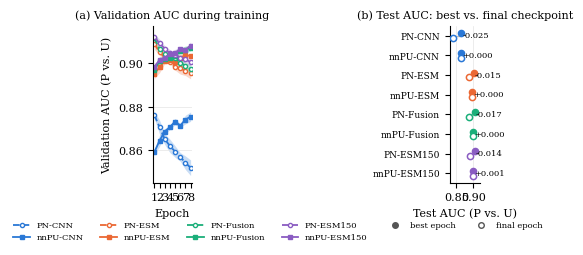

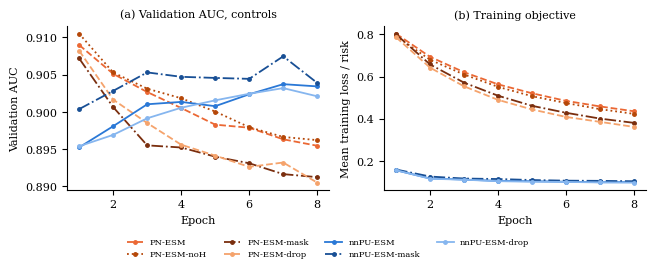

In [21]:
plt.rcParams.update({'font.family': 'serif', 'font.size': 8, 'axes.spines.top': False, 'axes.spines.right': False, 'pdf.fonttype': 42})
col = {'CNN': '#2a78d6', 'ESM': '#eb6834', 'Fusion': '#1baf7a', 'ESM150': '#8a5cc2'}
arches = ['CNN', 'ESM', 'Fusion'] + (['ESM150'] if RUN_LARGE else [])
fig = plt.figure(figsize=(6.6, 2.7)); gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 1, .02])
ax0 = fig.add_subplot(gs[0]); ax1 = fig.add_subplot(gs[1])
for a_ in arches:
    for loss_, ls_, mk_ in [('PN', '--', 'o'), ('nnPU', '-', 's')]:
        g_ = cv[cv.model == f'{loss_}-{a_}'].groupby('epoch').val_auc.agg(['mean', 'std'])
        ax0.plot(g_.index, g_['mean'], ls=ls_, marker=mk_, ms=3, lw=1.3, color=col[a_], mfc='white' if loss_ == 'PN' else col[a_], label=f'{loss_}-{a_}')
        ax0.fill_between(g_.index, g_['mean'] - g_['std'].fillna(0), g_['mean'] + g_['std'].fillna(0), color=col[a_], alpha=.25, lw=0)
ax0.set_xlabel('Epoch'); ax0.set_ylabel('Validation AUC (P vs. U)'); ax0.set_title('(a) Validation AUC during training', fontsize=8)
ax0.set_xticks(range(1, EPOCHS + 1)); ax0.grid(axis='y', color='#e5e5e5', lw=.5)
ax0.legend(fontsize=6, frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.95, -0.2))
names = [f'{l_}-{a_}' for a_ in arches for l_ in ['PN', 'nnPU']][::-1]
for i, n_ in enumerate(names):
    b_, f_ = ms(n_, 'best', 'AUC')[0], ms(n_, 'final', 'AUC')[0]; c_ = col[n_.split('-')[1]]
    ax1.plot([b_, f_], [i, i], color='#bbb', lw=1, zorder=1)
    ax1.scatter([b_], [i + .12], s=20, color=c_, zorder=3); ax1.scatter([f_], [i - .12], s=20, facecolor='white', edgecolor=c_, lw=1.1, zorder=3)
    ax1.text(max(b_, f_) + .003, i, f'{round(f_, 3) - round(b_, 3):+.3f}', va='center', fontsize=6)
ax1.set_yticks(range(len(names))); ax1.set_yticklabels(names, fontsize=6.5); ax1.set_xlabel('Test AUC (P vs. U)')
ax1.set_title('(b) Test AUC: best vs. final checkpoint', fontsize=8); ax1.grid(axis='x', color='#e5e5e5', lw=.5)
h_ = [plt.Line2D([], [], marker='o', ls='', color='#555', ms=4, label='best epoch'),
      plt.Line2D([], [], marker='o', ls='', mfc='white', mec='#555', ms=4, label='final epoch')]
ax1.legend(handles=h_, fontsize=6, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
lo_ = min(ms(n_, k_, 'AUC')[0] for n_ in names for k_ in ['best', 'final']); ax1.set_xlim(lo_ - .01, ax1.get_xlim()[1] + .012)
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig_dynamics.pdf', bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(6.6, 2.4))
cc = {'PN-ESM': ('#eb6834', '--'), 'PN-ESM-noH': ('#b54708', ':'), 'PN-ESM-mask': ('#7a2e0e', '-.'), 'PN-ESM-drop': ('#f5a36c', '--'),
      'nnPU-ESM': ('#2a78d6', '-'), 'nnPU-ESM-mask': ('#184f95', '-.'), 'nnPU-ESM-drop': ('#86b6ef', '-')}
for m_, (c_, ls_) in cc.items():
    g_ = cv[cv.model == m_].groupby('epoch')
    ax[0].plot(g_.val_auc.mean().index, g_.val_auc.mean(), ls=ls_, color=c_, lw=1.3, marker='o', ms=2.5, label=m_)
    ax[1].plot(g_.train_loss.mean().index, g_.train_loss.mean(), ls=ls_, color=c_, lw=1.3, marker='o', ms=2.5)
ax[0].set_title('(a) Validation AUC, controls', fontsize=8); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Validation AUC')
ax[1].set_title('(b) Training objective', fontsize=8); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Mean training loss / risk')
fig.legend(*ax[0].get_legend_handles_labels(), fontsize=6, frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig_controls.pdf', bbox_inches='tight'); plt.show()

## 11. Selection bias: results by annotation density of the test proteins (R2.1)

In [22]:
# R2.1 (c): selection bias -- does performance depend on how heavily a protein is annotated?
# Test proteins with at least one P site are split into tertiles of annotation density (P sites per S/T/Y).
# Under SCAR the P vs U AUC should be similar across tertiles; a strong trend means the labels (and hence the
# P vs U metric) are shaped by how well-studied a protein is.
tp_ = data[te].groupby('accession').label.agg(nP=lambda s_: int((s_ == 'P').sum()), nH=lambda s_: int((s_ == 'H').sum()), n='size')
tp_['density'] = tp_.nP / tp_.n
ann = tp_[tp_.nP > 0]
n_q = 3 if len(ann) >= 3 else 1
tp_['stratum'] = 'no P site'
tp_.loc[ann.index, 'stratum'] = (pd.qcut(ann.density.rank(method='first'), 3, labels=['low', 'mid', 'high']).astype(str)
                                 if n_q == 3 else 'all')
strat = data.accession.map(tp_.stratum).values
SM = [m_ for m_ in ['PN-ESM', 'nnPU-ESM', 'PN-Fusion', 'nnPU-Fusion'] if (m_, 'best') in SC]
strat_rows, lines = [], []
for s_name in (['low', 'mid', 'high'] if n_q == 3 else ['all']) + ['no P site']:
    sub = te & (strat == s_name)
    row = dict(stratum=s_name, proteins=int((tp_.stratum == s_name).sum()), P=int((sub & (L == 'P')).sum()),
               H=int((sub & (L == 'H')).sum()), U=int((sub & (L == 'U')).sum()))
    # mean percentile of the U residues' scores within all test U residues (higher = U looks more site-like)
    for m_ in SM:
        for k_ in ['best', 'final']:
            sc_ = np.mean(SC[(m_, k_)], axis=0)
            mP = sub & np.isin(L, ['P', 'U']); mH = sub & np.isin(L, ['H', 'U'])
            row[f'{m_}|{k_}|AUC'] = float(roc_auc_score(L[mP] == 'P', sc_[mP])) if row['P'] > 0 else np.nan
            row[f'{m_}|{k_}|HP_AUC'] = float(roc_auc_score(L[mH] == 'H', sc_[mH])) if row['H'] > 0 else np.nan
            u_all = np.sort(sc_[te & (L == 'U')])
            row[f'{m_}|{k_}|U_pct'] = float(np.searchsorted(u_all, sc_[sub & (L == 'U')]).mean() / len(u_all))
    strat_rows.append(row)
SR = pd.DataFrame(strat_rows); SR.to_csv(f'{OUT}/stratified_by_annotation.csv', index=False); display(SR)
f3 = lambda v: '--' if (v is None or (isinstance(v, float) and np.isnan(v))) else f'{v:.3f}'
for r_ in strat_rows:
    lines.append(f"{r_['stratum']} & {r_['proteins']:,} & {r_['P']:,} & {r_['U']:,} & " +
                 ' & '.join(f3(r_.get(f'{m_}|{k_}|AUC')) for m_, k_ in [('PN-ESM', 'best'), ('nnPU-ESM', 'best'), ('PN-ESM', 'final'), ('nnPU-ESM', 'final')])
                 + f" & {f3(r_.get('nnPU-ESM|best|U_pct'))}" + r' \\')
open(f'{OUT}/tables/tab_strata.tex', 'w').write('\n'.join(lines))
put('strata', strat_rows)

,stratum,proteins,P,H,U,PN-ESM|best|AUC,PN-ESM|best|HP_AUC,PN-ESM|best|U_pct,PN-ESM|final|AUC,PN-ESM|final|HP_AUC,...,PN-Fusion|best|U_pct,PN-Fusion|final|AUC,PN-Fusion|final|HP_AUC,PN-Fusion|final|U_pct,nnPU-Fusion|best|AUC,nnPU-Fusion|best|HP_AUC,nnPU-Fusion|best|U_pct,nnPU-Fusion|final|AUC,nnPU-Fusion|final|HP_AUC,nnPU-Fusion|final|U_pct
0,low,438,769,397,70746,0.900746,0.893637,0.460642,0.887057,0.873259,...,0.462527,0.906457,0.884563,0.468640,0.898081,0.898171,0.462852,0.898406,0.897457,0.462814
1,mid,437,1593,331,45982,0.898902,0.854721,0.522229,0.887080,0.835254,...,0.519649,0.902276,0.851084,0.519702,0.896851,0.849789,0.523324,0.897085,0.849231,0.523718
2,high,438,3797,483,35882,0.873764,0.820240,0.586979,0.866118,0.808413,...,0.584555,0.876501,0.815643,0.579620,0.871187,0.816542,0.590860,0.870899,0.814776,0.590956
3,no P site,366,0,832,36901,NaN,0.831879,0.463167,NaN,0.799524,...,0.465123,NaN,0.828425,0.458138,NaN,0.834232,0.453791,NaN,0.834370,0.453280


[{'stratum': 'low',
  'proteins': 438,
  'P': 769,
  'H': 397,
  'U': 70746,
  'PN-ESM|best|AUC': 0.9007457933815278,
  'PN-ESM|best|HP_AUC': 0.8936366955371119,
  'PN-ESM|best|U_pct': 0.4606416354196082,
  'PN-ESM|final|AUC': 0.8870567270879538,
  'PN-ESM|final|HP_AUC': 0.8732591516064031,
  'PN-ESM|final|U_pct': 0.4746474424064651,
  'nnPU-ESM|best|AUC': 0.8924428247254037,
  'nnPU-ESM|best|HP_AUC': 0.8964912329424006,
  'nnPU-ESM|best|U_pct': 0.46263099427193594,
  'nnPU-ESM|final|AUC': 0.8933705929492923,
  'nnPU-ESM|final|HP_AUC': 0.8951035388886526,
  'nnPU-ESM|final|U_pct': 0.46331302462660895,
  'PN-Fusion|best|AUC': 0.9084913732113018,
  'PN-Fusion|best|HP_AUC': 0.9004611238801514,
  'PN-Fusion|best|U_pct': 0.46252747230818647,
  'PN-Fusion|final|AUC': 0.9064569242143462,
  'PN-Fusion|final|HP_AUC': 0.8845631524876911,
  'PN-Fusion|final|U_pct': 0.46864010984144183,
  'nnPU-Fusion|best|AUC': 0.8980811112131876,
  'nnPU-Fusion|best|HP_AUC': 0.8981706008816727,
  'nnPU-Fusion|be

### MusiteDeep, run automatically on the strict-test proteins (R1, R2.4)

In [23]:
# R1, R2.4: an established predictor run automatically on the SAME strict-test residues -- MusiteDeep (Wang et al., NAR 2020).
# Its released models (Keras 2.2.4 / TF 1.12) are run unchanged through a small compatibility layer on TF 2.x + tf_keras,
# in a separate environment (no effect on this notebook's packages). Output: external/MusiteDeep_NN.txt (read in Section 12).
# MusiteDeep was trained on UniProt sites, so test proteins may be in its training data: its numbers are an upper bound.
RUN_MUSITEDEEP = True
MD_BASE = '/content' if os.path.isdir('/content') else '/tmp'
MD_REPO, MD_ENV = f'{MD_BASE}/MusiteDeep_web', f'{MD_BASE}/mdenv'
MD_COMPAT = r'''
import sys, types, tensorflow as tf, tf_keras
K = tf_keras.backend
def _batch_dot_224(x, y, axes=None):          # Keras 2.2.4 semantics (changed in Keras 2.3)
    if isinstance(axes, int): axes = (axes, axes)
    xn, yn = K.ndim(x), K.ndim(y)
    if axes is None: axes = [xn - 1, yn - 2]
    if xn > yn: diff = xn - yn; y = tf.reshape(y, tf.concat([tf.shape(y), [1] * diff], 0))
    elif yn > xn: diff = yn - xn; x = tf.reshape(x, tf.concat([tf.shape(x), [1] * diff], 0))
    else: diff = 0
    if K.ndim(x) == 2 and K.ndim(y) == 2:
        out = tf.reduce_sum(x * y, axes[0]) if axes[0] == axes[1] else tf.reduce_sum(tf.transpose(x, [1, 0]) * y, axes[1])
    else:
        adj_x = None if axes[0] == K.ndim(x) - 1 else True
        adj_y = True if axes[1] == K.ndim(y) - 1 else None
        out = tf.matmul(x, y, adjoint_a=adj_x, adjoint_b=adj_y)
    if diff:
        idx = xn + yn - 3 if xn > yn else xn - 1
        out = tf.squeeze(out, list(range(idx, idx + diff)))
    if K.ndim(out) == 1: out = K.expand_dims(out, 1)
    return out
K.batch_dot = _batch_dot_224
L = tf_keras.layers
ns = lambda **kw: types.SimpleNamespace(**kw)
mods = {'keras': tf_keras, 'keras.layers': L, 'keras.models': tf_keras.models, 'keras.backend': K,
        'keras.callbacks': tf_keras.callbacks, 'keras.optimizers': tf_keras.optimizers, 'keras.regularizers': tf_keras.regularizers,
        'keras.utils': tf_keras.utils, 'keras.initializers': tf_keras.initializers, 'keras.activations': tf_keras.activations,
        'keras.constraints': tf_keras.constraints, 'keras.layers.core': L, 'keras.layers.convolutional': L,
        'keras.layers.merge': L, 'keras.layers.normalization': L,
        'keras.engine': ns(InputSpec=L.InputSpec, Layer=L.Layer), 'keras.engine.topology': ns(Layer=L.Layer),
        'keras.utils.np_utils': ns(to_categorical=tf_keras.utils.to_categorical),
        'LossCheckPoint': ns(LossModelCheckpoint=tf_keras.callbacks.ModelCheckpoint)}
for k, v in mods.items(): sys.modules[k] = v
for k, v in mods.items():
    if '.' in k:
        p, c = k.rsplit('.', 1)
        try: setattr(mods[p], c, v)
        except Exception: pass
tf_keras.models.Input = L.Input
import os, runpy
md = sys.argv[1]; sys.path.insert(0, md); os.chdir(md)
sys.argv = ['predict_multi_batch.py'] + sys.argv[2:]
runpy.run_path('predict_multi_batch.py', run_name='__main__')
'''
def md_patch(md):
    """Minimal source edits needed by TF 2.x (no change to the models or the prediction logic)."""
    def edit(f, pairs, regex=()):
        p = os.path.join(md, f); s = open(p, newline='').read().replace('\r\n', '\n')
        for a, b in pairs: s = s.replace(a, b)
        for a, b in regex: s = re.sub(a, b, s)
        open(p, 'w').write(s)
    edit('multiCNN_callback.py', [], [(r'^', 'from keras import backend as K\n'), (r'([A-Za-z_]+)\._keras_shape\[([0-9])\]', r'K.int_shape(\1)[\2]')])
    edit('capsulenet_callback.py', [], [(r'([A-Za-z_]+)\._keras_shape\[([0-9])\]', r'K.int_shape(\1)[\2]')])
    edit('capsulelayers.py', [('tf.nn.softmax(b, dim=1)', 'tf.nn.softmax(b, axis=1)')])
    edit('attention.py', [('        x=x[:,:self.mydeletedim]\n        return K.batch_flatten(x)',
                           '        x=x[:,:self.mydeletedim]\n        return K.reshape(x, (-1, self.mydeletedim))')])
    open(os.path.join(md, '.patched'), 'w').write('ok')

def sh(cmd, **kw):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, **kw)
    if r.returncode: print(cmd, '\n', r.stdout[-1500:], r.stderr[-3000:])
    return r.returncode == 0

md_parts = sorted(glob.glob(f'{OUT}/external_input/strict_test_part*.fasta'))
os.makedirs(os.path.join(DRIVE_DIR, 'external'), exist_ok=True)
todo = [p_ for p_ in md_parts if not os.path.exists(os.path.join(DRIVE_DIR, 'external', 'MusiteDeep_' + re.search(r'part(\d+)\.fasta$', p_).group(1) + '.txt'))]
if RUN_MUSITEDEEP and todo:
    t0_ = time.time(); ok = True
    if not os.path.isdir(f'{MD_REPO}/MusiteDeep/models/Phosphotyrosine'):
        ok = sh(f'rm -rf {MD_REPO} && git clone -q --depth 1 --filter=blob:none --sparse https://github.com/duolinwang/MusiteDeep_web.git {MD_REPO}'
                f' && cd {MD_REPO} && git sparse-checkout set --no-cone "/MusiteDeep/*.py" "/MusiteDeep/models/Phosphoserine_Phosphothreonine/" "/MusiteDeep/models/Phosphotyrosine/" "/MusiteDeep/testdata/Phosphorylation/"')
    md_dir = f'{MD_REPO}/MusiteDeep'
    if ok and not os.path.exists(f'{md_dir}/.patched'): md_patch(md_dir)
    if ok and not os.path.exists(f'{MD_ENV}/bin/python'):
        ok = sh(f'pip -q install uv && uv venv -q {MD_ENV} --python {sys.executable} && '
                f'uv pip install -q --python {MD_ENV}/bin/python tensorflow-cpu tf_keras pandas scikit-learn h5py')
    if ok:
        open(f'{MD_REPO}/run_md.py', 'w').write(MD_COMPAT)
        rev = subprocess.run(f'git -C {MD_REPO} rev-parse HEAD', shell=True, capture_output=True, text=True).stdout.strip()
        put('musitedeep', dict(repo='https://github.com/duolinwang/MusiteDeep_web', commit=rev, models='Phosphoserine_Phosphothreonine;Phosphotyrosine'))
        for p_ in todo:            # one part at a time, so an interrupted session resumes
            nn_ = re.search(r'part(\d+)\.fasta$', p_).group(1); pre = f'{MD_BASE}/md_out/part{nn_}'
            if sh(f'{MD_ENV}/bin/python {MD_REPO}/run_md.py {md_dir} -input {p_} -output {pre} '
                  f'-model-prefix "models/Phosphoserine_Phosphothreonine;Phosphotyrosine"', env={**os.environ, 'TF_CPP_MIN_LOG_LEVEL': '3'}):
                shutil.copy(f'{pre}_results.txt', os.path.join(DRIVE_DIR, 'external', f'MusiteDeep_{nn_}.txt'))
                print(f'MusiteDeep part {nn_} done ({(time.time() - t0_) / 60:.1f} min)')
    else:
        print('MusiteDeep could not be set up (see message above); Section 12 runs with whatever external files exist.')
# v5: MusiteDeep's own training/test data (used in Section 12 to build a leakage-free comparison)
MD_DATA = f'{MD_REPO}/MusiteDeep/testdata/Phosphorylation'
if RUN_MUSITEDEEP and not os.path.isdir(MD_DATA):
    if os.path.isdir(f'{MD_REPO}/.git'):
        sh(f'cd {MD_REPO} && git sparse-checkout add "/MusiteDeep/testdata/Phosphorylation/"')
    else:
        sh(f'rm -rf {MD_REPO} && git clone -q --depth 1 --filter=blob:none --sparse https://github.com/duolinwang/MusiteDeep_web.git {MD_REPO}'
           f' && cd {MD_REPO} && git sparse-checkout set --no-cone "/MusiteDeep/testdata/Phosphorylation/"')
print('MusiteDeep training data files:', sorted(glob.glob(f'{MD_DATA}/*/*annotated.fasta')))
print('MusiteDeep parts available:', len(glob.glob(os.path.join(DRIVE_DIR, 'external', 'MusiteDeep_*.txt'))), 'of', len(md_parts))

MusiteDeep part 01 done (8.4 min)
MusiteDeep part 02 done (13.8 min)
MusiteDeep part 03 done (19.8 min)
MusiteDeep part 04 done (27.1 min)
MusiteDeep part 05 done (34.1 min)
MusiteDeep part 06 done (40.0 min)
MusiteDeep part 07 done (46.1 min)
MusiteDeep part 08 done (46.9 min)
MusiteDeep training data files: ['/content/MusiteDeep_web/MusiteDeep/testdata/Phosphorylation/ST/test_allspecies_sequences_annotated.fasta', '/content/MusiteDeep_web/MusiteDeep/testdata/Phosphorylation/ST/train_allspecies_sequences_annotated.fasta', '/content/MusiteDeep_web/MusiteDeep/testdata/Phosphorylation/Y/test_allspecies_sequences_annotated.fasta', '/content/MusiteDeep_web/MusiteDeep/testdata/Phosphorylation/Y/train_allspecies_sequences_annotated.fasta']
MusiteDeep parts available: 8 of 8


## 12. Established predictors on exactly the same residues (R1, R2.4)

In [24]:
# R1, R2.4: established predictors on the SAME test residues.
# Run any tool on outputs_v4/external_input/*.fasta and save its predictions as DRIVE_DIR/external/<ToolName>.csv
# (or .tsv) with columns: accession, position, score  (aliases accepted: id/protein/uniprot, pos/site/residue, prob/probability).
# v5: MusiteDeep is run automatically in the previous cell (external/MusiteDeep_NN.txt). Raw text output of other tools
# (e.g. NetPhos 3.1) can be saved unchanged as external/<ToolName>.txt; parts <ToolName>_1.txt, _2.txt ... are merged.
# Accessions such as 'sp|P12345|NAME' or 'P12345-1' are normalised. Only residues the tool scored are compared, and our
# models are evaluated on exactly the same residues. NOTE: test proteins may be in a tool's own training data, so its
# numbers are optimistic (an upper bound for that tool).
EXT_DIR = os.path.join(DRIVE_DIR, 'external')
ext_files = sorted(sum([glob.glob(f'{EXT_DIR}/*.{e}') for e in ['csv', 'tsv', 'txt', 'out', 'gff']], [])) if os.path.isdir(EXT_DIR) else []
def norm_acc(a):
    # 'sp|P12345|NAME' -> 'P12345'; isoform accessions (P12345-2) are kept as they are, because their positions
    # differ from the canonical sequence used here (same rule as v3)
    a = str(a).strip()
    if '|' in a: a = a.split('|')[1]
    return a.split()[0]
def parse_raw(path):
    # v5: raw server output, saved as-is to external/<Tool>.txt
    #  NetPhos 3.1 :  '# <seq> <pos> <S/T/Y> <context> <score> <kinase> <answer>'  (or GFF: seq src feat pos pos score ...)
    #  MusiteDeep / FASTA-block outputs: '>seq' header, then rows '<pos> <S/T/Y> ... <score(s)>'
    rows, cur = [], None
    for line in open(path, errors='ignore'):
        line = line.rstrip('\n')
        if line.startswith('>'): cur = norm_acc(line[1:]); continue
        tok = line.lstrip('#').split()
        if len(tok) == 1 and not tok[0][0].isdigit(): cur = norm_acc(tok[0]); continue        # bare protein-ID line
        if len(tok) >= 6 and tok[1].isdigit() and tok[2] in ('S', 'T', 'Y'):                      # NetPhos text
            try: rows.append((norm_acc(tok[0]), int(tok[1]), float(tok[4]))); continue
            except ValueError: pass
        f = line.split('\t')
        if len(f) >= 6 and f[3].isdigit() and not line.startswith('#'):                         # GFF
            try: rows.append((norm_acc(f[0]), int(f[3]), float(f[5]))); continue
            except ValueError: pass
        if cur and len(tok) >= 3 and tok[0].isdigit() and tok[1] in ('S', 'T', 'Y'):            # FASTA-block tables
            sc = [float(x) for x in re.findall(r'(?<![=\w])(\d*\.\d+|[01])(?![\w.])', ' '.join(tok[2:]))]
            if sc: rows.append((cur, int(tok[0]), max(sc)))
    return pd.DataFrame(rows, columns=['accession', 'pos', 'score'])
def load_ext(path):
    if path.endswith(('.txt', '.out', '.gff')):
        t = parse_raw(path)
        if len(t) == 0: print('could not parse', path); return t
        return t.groupby(['accession', 'pos'], as_index=False).score.max()
    t = pd.read_csv(path, sep='\t' if path.endswith('.tsv') else ',')
    cols = {c.lower().strip(): c for c in t.columns}
    pick = lambda names: next(cols[n] for n in names if n in cols)
    t = pd.DataFrame({'accession': t[pick(['accession', 'acc', 'id', 'protein', 'uniprot', 'sequence_id', 'seqname'])].map(norm_acc),
                      'pos': pd.to_numeric(t[pick(['position', 'pos', 'site', 'residue', 'residue_position'])], errors='coerce'),
                      'score': pd.to_numeric(t[pick(['score', 'prob', 'probability', 'prediction'])], errors='coerce')}).dropna()
    return t.astype({'pos': int}).groupby(['accession', 'pos'], as_index=False).score.max()
ref_models = [m_ for m_ in [max([m_ for m_ in NEU if m_.startswith('nnPU')], key=lambda m_: ms(m_, 'best', 'AUC')[0]),
                            max([m_ for m_ in NEU if m_.startswith('PN')], key=lambda m_: ms(m_, 'best', 'AUC')[0]), 'PSSM']]
ext_rows, lines, TOOL_SC = [], [], {}
key_te = pd.MultiIndex.from_arrays([data.accession.values, data.pos.values])
TOOLS = {}
for path in ext_files: TOOLS.setdefault(re.sub(r'_\d+$', '', os.path.splitext(os.path.basename(path))[0]), []).append(path)
for tool, paths in TOOLS.items():
    et = pd.concat([load_ext(p_) for p_ in paths]).groupby(['accession', 'pos'], as_index=False).score.max()
    sc_map = dict(zip(zip(et.accession, et.pos), et.score))
    tool_sc = np.array([sc_map.get(k, np.nan) for k in key_te], dtype=np.float64)
    TOOL_SC[tool] = tool_sc
    cov = te & ~np.isnan(tool_sc)
    row = dict(tool=tool, residues_scored=int(cov.sum()), coverage=float(cov.sum() / te.sum()))
    for pos in ['P', 'H']:
        m = cov & np.isin(L, [pos, 'U'])
        if m.sum() == 0 or (L[m] == pos).sum() == 0: continue
        y = L[m] == pos
        row[f'{pos}_AUC_tool'] = float(roc_auc_score(y, tool_sc[m]))
        if pos == 'P': row['AUPRC_tool'] = float(average_precision_score(y, tool_sc[m]))
        up, inv = np.unique(prot_idx[m], return_inverse=True); g = np.random.default_rng(3)
        ot = np.argsort(tool_sc[m], kind='mergesort')
        for rm in ref_models:
            sc_ = np.mean(SC[(rm, ck(rm))], axis=0)[m]; om = np.argsort(sc_, kind='mergesort')
            dpt = roc_auc_score(y, sc_) - row[f'{pos}_AUC_tool']; d = np.empty(N_BOOT)
            for b in range(N_BOOT):
                w = np.bincount(g.integers(0, len(up), len(up)), minlength=len(up))[inv].astype(np.float64)
                d[b] = wauc(y[om], w[om]) - wauc(y[ot], w[ot])
            row[f'{pos}_AUC_{rm}'] = float(roc_auc_score(y, sc_))
            row[f'{pos}_diff_{rm}'] = (float(dpt),) + tuple(float(x) for x in np.percentile(d, [2.5, 97.5]))
    ext_rows.append(row); print(row)
    rm0 = ref_models[0]
    if 'P_AUC_tool' in row:
        dd = row[f'P_diff_{rm0}']
        lines.append(f"{tool} & {row['residues_scored']:,} ({100 * row['coverage']:.0f}\\%) & {row['P_AUC_tool']:.3f} & {row[f'P_AUC_{rm0}']:.3f} & "
                     + cell(dd) + ' & ' + (f"{row['H_AUC_tool']:.3f}" if 'H_AUC_tool' in row else '--') + r' \\')
# v5 (R1, R2.4): leakage-free MusiteDeep comparison. MusiteDeep's training/test data are public (MD_DATA); residues it was
# trained on as positives -- and proteins it saw -- are removed, so neither side has seen the evaluated positives.
def md_known():
    seqs, acc_seen, pos_sites = set(), set(), set()
    for f_ in glob.glob(f'{MD_DATA}/*/*annotated.fasta'):
        for rec in open(f_).read().split('>')[1:]:
            head, *body = rec.strip().split('\n'); raw_ = ''.join(body).replace(' ', '')
            seq = raw_.replace('#', ''); acc_ = norm_acc(head.split()[0]); acc_seen.add(acc_); seqs.add(seq)
            j_ = 0
            for ch in raw_:
                if ch == '#': pos_sites.add((seq, j_)); continue
                j_ += 1
    return seqs, acc_seen, pos_sites
if 'MusiteDeep' in TOOL_SC and 'MD_DATA' in globals() and glob.glob(f'{MD_DATA}/*/*annotated.fasta'):
    md_seqs, md_acc, md_pos = md_known()
    seq_of = dict(zip(prot.Accession, prot.Sequence)); acc_v = data.accession.values; pos_v = data.pos.values
    p_seen = np.array([a_ in md_acc or seq_of[a_] in md_seqs for a_ in acc_v])
    p_samesq = np.array([seq_of[a_] in md_seqs for a_ in acc_v])
    site_pos = np.array([(seq_of[a_], int(p_)) in md_pos for a_, p_ in zip(acc_v, pos_v)])
    put('musitedeep_overlap', dict(strict_proteins=int(len(set(acc_v[ts]))), strict_proteins_seen=int(len(set(acc_v[ts & p_seen]))),
                                   strict_P=int((ts & (L == 'P')).sum()), strict_P_trained_as_positive=int((ts & (L == 'P') & site_pos).sum())))
    print('MusiteDeep training overlap:', NUM['musitedeep_overlap'])
    tsc = TOOL_SC['MusiteDeep']; cov0 = te & ~np.isnan(tsc)
    for nm_, elig, P_ok in [('unseen proteins', ~p_seen, np.ones(len(L), bool)),
                            ('positives new to MusiteDeep', ~p_seen | p_samesq, ~site_pos)]:
        m = cov0 & elig & (((L == 'P') & P_ok) | (L == 'U')); y = L[m] == 'P'
        row = dict(tool=f'MusiteDeep ({nm_})', residues_scored=int(m.sum()), coverage=float(m.sum() / max(cov0.sum(), 1)), n_P=int(y.sum()))
        if y.sum() >= 2 and (~y).sum() >= 2:
            row['P_AUC_tool'] = float(roc_auc_score(y, tsc[m])); row['AUPRC_tool'] = float(average_precision_score(y, tsc[m]))
            up, inv = np.unique(prot_idx[m], return_inverse=True); g = np.random.default_rng(4); ot = np.argsort(tsc[m], kind='mergesort')
            for rm in ref_models:
                sc_ = np.mean(SC[(rm, ck(rm))], axis=0)[m]; om = np.argsort(sc_, kind='mergesort'); d = np.empty(N_BOOT)
                for b in range(N_BOOT):
                    w = np.bincount(g.integers(0, len(up), len(up)), minlength=len(up))[inv].astype(np.float64)
                    d[b] = wauc(y[om], w[om]) - wauc(y[ot], w[ot])
                row[f'P_AUC_{rm}'] = float(roc_auc_score(y, sc_))
                row[f'P_diff_{rm}'] = (float(roc_auc_score(y, sc_) - row['P_AUC_tool']),) + tuple(float(x) for x in np.percentile(d, [2.5, 97.5]))
            dd = row[f'P_diff_{ref_models[0]}']
            lines.append(f"{row['tool']} & {row['residues_scored']:,} ({row['n_P']:,} P) & {row['P_AUC_tool']:.3f} & {row[f'P_AUC_{ref_models[0]}']:.3f} & " + cell(dd) + r' & -- \\')
        ext_rows.append(row); print(row)
if ext_files:
    open(f'{OUT}/tables/tab_external.tex', 'w').write('\n'.join(lines))
    pd.DataFrame(ext_rows).to_csv(f'{OUT}/external_comparison.csv', index=False)
else:
    print(f'No external predictions found in {EXT_DIR}/. To compare with established tools, run them on '
          f'{OUT}/external_input/*.fasta, save <ToolName>.csv (accession, position, score) there, and rerun this cell.')
put('external', ext_rows)

{'tool': 'MusiteDeep', 'residues_scored': 170444, 'coverage': 0.8620778603329068, 'P_AUC_tool': 0.944698005921425, 'AUPRC_tool': 0.4058126295629479, 'P_AUC_nnPU-Fusion': 0.9043842686187793, 'P_diff_nnPU-Fusion': (-0.04031373730264576, -0.04528645806482401, -0.03568723274351926), 'P_AUC_PN-ESM150': 0.9107608410582416, 'P_diff_PN-ESM150': (-0.03393716486318343, -0.03915165489644106, -0.029033826402666937), 'P_AUC_PSSM': 0.8373902592648994, 'P_diff_PSSM': (-0.10730774665652565, -0.11609928163960509, -0.09888830461385052), 'H_AUC_tool': 0.9301247652699282, 'H_AUC_nnPU-Fusion': 0.844252845722087, 'H_diff_nnPU-Fusion': (-0.08587191954784112, -0.10725092859439743, -0.06469767886508469), 'H_AUC_PN-ESM150': 0.8383061085040686, 'H_diff_PN-ESM150': (-0.09181865676585954, -0.12127979070130822, -0.06351641468607651), 'H_AUC_PSSM': 0.7693592970424044, 'H_diff_PSSM': (-0.1607654682275238, -0.18328597894914953, -0.1389051940007642)}
MusiteDeep training overlap: {'strict_proteins': 1434, 'strict_protei

[{'tool': 'MusiteDeep',
  'residues_scored': 170444,
  'coverage': 0.8620778603329068,
  'P_AUC_tool': 0.944698005921425,
  'AUPRC_tool': 0.4058126295629479,
  'P_AUC_nnPU-Fusion': 0.9043842686187793,
  'P_diff_nnPU-Fusion': (-0.04031373730264576,
   -0.04528645806482401,
   -0.03568723274351926),
  'P_AUC_PN-ESM150': 0.9107608410582416,
  'P_diff_PN-ESM150': (-0.03393716486318343,
   -0.03915165489644106,
   -0.029033826402666937),
  'P_AUC_PSSM': 0.8373902592648994,
  'P_diff_PSSM': (-0.10730774665652565,
   -0.11609928163960509,
   -0.09888830461385052),
  'H_AUC_tool': 0.9301247652699282,
  'H_AUC_nnPU-Fusion': 0.844252845722087,
  'H_diff_nnPU-Fusion': (-0.08587191954784112,
   -0.10725092859439743,
   -0.06469767886508469),
  'H_AUC_PN-ESM150': 0.8383061085040686,
  'H_diff_PN-ESM150': (-0.09181865676585954,
   -0.12127979070130822,
   -0.06351641468607651),
  'H_AUC_PSSM': 0.7693592970424044,
  'H_diff_PSSM': (-0.1607654682275238,
   -0.18328597894914953,
   -0.1389051940007642)

## 13. Validity of the hidden positives and independent validation of the candidates (R1, R2.5)

In [27]:
# R1, R2.5: how valid are the orthology-transferred hidden positives, and are the top candidates supported independently?
# (a) H/P motif agreement with a bootstrap CI, overall and per residue type (no external data needed)
def counts_w(Z):                                  # Z: (n, 21) residue indices, 0 = padding / unknown
    M = np.zeros((21, Z.shape[1])); np.add.at(M, (Z, np.broadcast_to(np.arange(Z.shape[1]), Z.shape)), 1); return M[1:]
def prof(Z): M = counts_w(Z); return M / M.sum(0, keepdims=True)
Xall = np.array([[IDX.get(c_, 0) for c_ in w] for w in ds.window], dtype=np.int64); Lds, Rds = ds.label.values, ds.res.values
def motif_check(res_=None, n_b=100):
    """H/P motif agreement, plus a 'ceiling': how well a random subset of experimentally observed P sites of the same
    size agrees with the remaining P sites. If H agrees almost as well as P agrees with itself, the orthology-transferred
    labels carry the same kinase-motif signal as experimental sites (they may still contain some false sites)."""
    sel = lambda lab: (Lds == lab) & ((Rds == res_) if res_ else True)
    gU = np.random.default_rng(0); U_idx = np.where(sel('U'))[0]; U_idx = gU.choice(U_idx, min(100000, len(U_idx)), replace=False)
    fU = prof(Xall[U_idx]) + PSEUDO; enr = lambda idx: np.log2((prof(Xall[idx]) + PSEUDO) / fU)
    keep = [j for j in range(2 * WIN + 1) if j != WIN]
    corr = lambda e1, e2: float(np.corrcoef(e1[:, keep].ravel(), e2[:, keep].ravel())[0, 1])
    Pi, Hi = np.where(sel('P'))[0], np.where(sel('H'))[0]
    if len(Hi) < 20 or len(Pi) < 40: return None
    nA = min(len(Hi), len(Pi) // 2); g = np.random.default_rng(1); rH, rP = [], []
    for _ in range(n_b):
        perm = g.permutation(Pi); eB = enr(perm[nA:])                       # reference: the other P sites
        rP.append(corr(enr(perm[:nA]), eB)); rH.append(corr(enr(g.choice(Hi, nA, replace=False)), eB))
    rH, rP = np.array(rH), np.array(rP)
    return dict(r=corr(enr(Pi), enr(Hi)), n_H=int(len(Hi)), n_matched=int(nA), r_H_ref=float(rH.mean()), r_P_ref=float(rP.mean()),
                ratio=float(rH.mean() / rP.mean()), r_H_ref_ci=[float(x) for x in np.percentile(rH, [2.5, 97.5])],
                r_P_ref_ci=[float(x) for x in np.percentile(rP, [2.5, 97.5])])
put('motif_agreement', {str(k_): motif_check(k_) for k_ in [None, 'S', 'T', 'Y']})
print(NUM['motif_agreement'])

# (b) independent site sets: PhosphoSitePlus (free registration) and any extra_sites/*.csv (accession, position)
IND = {}
psp_file = next((f for f in os.listdir('.') if f.startswith('Phosphorylation_site_dataset')), None)
if psp_file:
    psp = pd.read_csv(psp_file, sep='\t', skiprows=3, compression='gzip' if psp_file.endswith('.gz') else None, low_memory=False)
    psp = psp[psp.ORGANISM == 'human'].copy()
    psp['acc'] = psp.ACC_ID.astype(str).str.strip()   # as in v3: isoform rows do not match canonical positions
    psp['pos'] = psp.MOD_RSD.str.extract(r'^[STY](\d+)-p')[0].astype(float)
    psp = psp.dropna(subset=['pos']); psp['pos'] = psp.pos.astype(int)
    lit = sum(pd.to_numeric(psp.get(col_, 0), errors='coerce').fillna(0) for col_ in ['LT_LIT'])
    ms_ = sum(pd.to_numeric(psp.get(col_, 0), errors='coerce').fillna(0) for col_ in ['MS_LIT', 'MS_CST'])
    IND['PhosphoSitePlus (any)'] = set(zip(psp.acc, psp.pos))
    strong = psp[(lit >= 1) | (ms_ >= 2)]
    IND['PhosphoSitePlus (LTP or >=2 HTP)'] = set(zip(strong.acc, strong.pos))
# v5: dbPTM experimental phosphorylation sites (free download, no registration) -> extra_sites/dbPTM_experimental.csv
DBPTM_URL = 'https://biomics.lab.nycu.edu.tw/dbPTM/download/experiment/Phosphorylation.gz'
db_csv = os.path.join(DRIVE_DIR, 'extra_sites', 'dbPTM_experimental.csv')
if not os.path.exists(db_csv):
    os.makedirs(os.path.dirname(db_csv), exist_ok=True); tmp_ = '/tmp/dbPTM_Phosphorylation.gz'
    if subprocess.run(['wget', '-q', '-O', tmp_, DBPTM_URL]).returncode == 0:
        acc_re = re.compile(r'^([OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2})$')
        ours = set(data.accession); rows_, ac_i, po_i = [], None, None
        opener = gzip.open if open(tmp_, 'rb').read(2) == b'\x1f\x8b' else open
        with opener(tmp_, 'rt', errors='ignore') as fh:
            for line in fh:
                f = line.rstrip('\n').split('\t')
                if ac_i is None:     # detect the accession and position columns from the first data row
                    ac_i = next((i for i, x in enumerate(f) if acc_re.match(x.strip())), None)
                    po_i = next((i for i, x in enumerate(f) if x.strip().isdigit() and i != ac_i), None)
                    if ac_i is None or po_i is None: ac_i = None; continue
                if len(f) > max(ac_i, po_i) and f[ac_i].strip() in ours and f[po_i].strip().isdigit():
                    rows_.append((f[ac_i].strip(), int(f[po_i])))
        if rows_:
            pd.DataFrame(sorted(set(rows_)), columns=['accession', 'position']).to_csv(db_csv, index=False)
            put('dbptm', dict(url=DBPTM_URL, sites_on_our_proteins=len(set(rows_)), md5=md5(tmp_)))
        else: print('dbPTM file downloaded but no rows could be parsed')
    else: print('dbPTM could not be downloaded; continuing without it')
for f_ in sorted(glob.glob(os.path.join(DRIVE_DIR, 'extra_sites', '*.csv'))):
    t_ = pd.read_csv(f_); cols = {c_.lower(): c_ for c_ in t_.columns}
    a_c = next(cols[n_] for n_ in ['accession', 'acc', 'uniprot', 'id'] if n_ in cols); p_c = next(cols[n_] for n_ in ['position', 'pos', 'site'] if n_ in cols)
    IND[os.path.splitext(os.path.basename(f_))[0]] = set(zip(t_[a_c].map(norm_acc), pd.to_numeric(t_[p_c], errors='coerce').dropna().astype(int)))
print('independent site sets:', {k_: len(v_) for k_, v_ in IND.items()} or 'none supplied')

keys_all = list(zip(data.accession.values, data.pos.values))
VAL_H, VAL_TOP, lines_v = [], [], []
cand_model = max([m_ for m_ in NEU if m_.startswith('nnPU')], key=lambda m_: ms(m_, 'best', 'AUC')[0])
pn_model = max([m_ for m_ in NEU if m_.startswith('PN')], key=lambda m_: ms(m_, 'best', 'AUC')[0])
put('candidate_model', cand_model); put('pn_reference_model', pn_model)
for src, S_ in IND.items():
    sup = np.array([k_ in S_ for k_ in keys_all])
    # H validity: how often is an H site independently supported, compared with P and with U residues?
    rate = {lab: float(sup[L == lab].mean()) for lab in ['P', 'H', 'U']}
    tbl = [[int((sup & (L == 'H')).sum()), int((~sup & (L == 'H')).sum())], [int((sup & (L == 'U')).sum()), int((~sup & (L == 'U')).sum())]]
    odds, p_f = sst.fisher_exact(tbl, alternative='greater')
    nH_, nU_ = int((L == 'H').sum()), int((L == 'U').sum())
    hv = dict(source=src, P_support=rate['P'], H_support=rate['H'], U_support=rate['U'], fisher_p=float(p_f),
              H_vs_U_fold=((tbl[0][0] + .5) / (nH_ + 1)) / ((tbl[1][0] + .5) / (nU_ + 1)))   # continuity-corrected
    # hidden-positive AUC on independently supported vs unsupported H sites (best checkpoints)
    for m_ in [cand_model, pn_model]:
        sc_ = np.mean(SC[(m_, 'best')], axis=0)
        for nm_, hm in [('supported', sup), ('unsupported', ~sup)]:
            mm = te & (((L == 'H') & hm) | (L == 'U'))
            hv[f'HP_AUC_{nm_}|{m_}'] = float(roc_auc_score(L[mm] == 'H', sc_[mm])) if ((L[mm] == 'H').sum() > 0) else np.nan
    VAL_H.append(hv)
    # candidate validation: top-K unlabeled residues of the strict test set, nnPU vs PN vs PSSM vs random expectation
    poolm = ts & (L == 'U'); N_ = int(poolm.sum()); Ksup = int((sup & poolm).sum()); base = Ksup / max(N_, 1)
    for m_ in [cand_model, pn_model, 'PSSM']:
        sc_ = np.mean(SC[(m_, ck(m_))], axis=0)
        order = np.where(poolm)[0][np.argsort(-sc_[poolm], kind='mergesort')]
        for K_ in TOPK:
            if K_ > N_: continue
            hits = int(sup[order[:K_]].sum())
            VAL_TOP.append(dict(source=src, model=m_, K=K_, hits=hits, precision=hits / K_, base_rate=base,
                                fold=(hits / K_) / max(base, 1e-12), p_hypergeom=float(sst.hypergeom.sf(hits - 1, N_, Ksup, K_))))
if IND:
    pd.DataFrame(VAL_H).to_csv(f'{OUT}/hidden_positive_validation.csv', index=False)
    VT = pd.DataFrame(VAL_TOP); VT.to_csv(f'{OUT}/candidate_validation.csv', index=False); display(pd.DataFrame(VAL_H)); display(VT)
    src0 = 'PhosphoSitePlus (LTP or >=2 HTP)' if 'PhosphoSitePlus (LTP or >=2 HTP)' in IND else list(IND)[0]
    for _, r_ in VT[VT.source == src0].iterrows():
        lines_v.append(f"{r_.model} & {r_.K} & {r_.hits} & {r_.precision:.3f} & {r_.base_rate:.3f} & {r_.fold:.1f} & "
                       + ('$<$0.001' if r_.p_hypergeom < 0.001 else f'{r_.p_hypergeom:.3f}') + r' \\')
    open(f'{OUT}/tables/tab_validation.tex', 'w').write('\n'.join(lines_v))
else:
    print('No independent site set supplied. Download Phosphorylation_site_dataset.gz from PhosphoSitePlus (free registration)'
          f' into {DRIVE_DIR}/ (and/or add extra_sites/*.csv) and rerun this cell.')
put('hidden_positive_validation', VAL_H); put('candidate_validation', VAL_TOP)
put('validation_source', src0 if IND else None)

# (c) candidate table for the paper (top 10 unlabeled strict-test residues of the best nnPU model)
avg = np.mean(SC[(cand_model, 'best')], axis=0)
cd = data.loc[ts & (L == 'U'), ['accession', 'pos', 'res', 'window']].copy(); cd['score'] = avg[ts & (L == 'U')]
cd = cd.nlargest(10, 'score').merge(prot[['Accession', 'Gene Name']], left_on='accession', right_on='Accession')
for src, S_ in IND.items(): cd[src] = ['yes' if (a_, int(p_)) in S_ else 'no' for a_, p_ in zip(cd.accession, cd.pos)]
psp_col = 'PhosphoSitePlus (any)'
cd['PhosphoSitePlus'] = cd[psp_col] if psp_col in cd else 'n/a'
# v5: the table's support column uses PhosphoSitePlus if supplied, otherwise the independent set used for validation
sup_col = psp_col if psp_col in cd else (src0 if IND else None)
cd['Support'] = cd[sup_col] if sup_col else 'n/a'; put('candidate_support_source', sup_col)
# v5: candidate stability across seeds -- overlap of each seed's top-100 (strict-test U residues)
pool_ = np.where(ts & (L == 'U'))[0]
tops = [set(pool_[np.argsort(-s_[pool_], kind='mergesort')[:100]]) for s_ in SC[(cand_model, 'best')]]
jac = [len(a_ & b_) / len(a_ | b_) for i_, a_ in enumerate(tops) for b_ in tops[i_ + 1:]]
top10 = set(pool_[np.argsort(-avg[pool_], kind='mergesort')[:10]])
put('candidate_stability', dict(model=cand_model, seeds=len(tops), top100_jaccard_mean=float(np.mean(jac)) if jac else None,
                                top100_jaccard_min=float(np.min(jac)) if jac else None,
                                top10_in_every_seed_top100=int(sum(all(i_ in t_ for t_ in tops) for i_ in top10))))
print('candidate stability:', NUM['candidate_stability'])
cd.to_csv(f'{OUT}/candidates.csv', index=False)
put('candidates_in_psp', int((cd.PhosphoSitePlus == 'yes').sum()) if psp_col in cd else None)
put('candidates_supported', int((cd.Support == 'yes').sum()) if sup_col else None)
lines = [f"{r_.accession} & {r_['Gene Name']} & {r_.res}{r_.pos} & \\texttt{{{r_.window[5:16]}}} & {r_.score:.2f} & {r_.Support} \\\\" for _, r_ in cd.iterrows()]
open(f'{OUT}/tables/tab_candidates.tex', 'w').write('\n'.join(lines)); display(cd)

{'None': {'r': 0.9184523727848787, 'n_H': 9870, 'n_matched': 9870, 'r_H_ref': 0.9160449409022093, 'r_P_ref': 0.9777898661837721, 'ratio': 0.9368525616628164, 'r_H_ref_ci': [0.912870574379028, 0.9194459835261859], 'r_P_ref_ci': [0.9726720088714389, 0.9820770545329696]}, 'S': {'r': 0.8994167481829981, 'n_H': 7750, 'n_matched': 7750, 'r_H_ref': 0.896676091899395, 'r_P_ref': 0.9710610548077657, 'ratio': 0.9233982636415213, 'r_H_ref_ci': [0.8923848325985421, 0.9012615880012524], 'r_P_ref_ci': [0.9644384355605444, 0.9761177043407849]}, 'T': {'r': 0.7721734142007776, 'n_H': 1382, 'n_matched': 1382, 'r_H_ref': 0.7617145010706714, 'r_P_ref': 0.868787367614825, 'ratio': 0.8767559583214104, 'r_H_ref_ci': [0.7466349541553992, 0.7773491370861493], 'r_P_ref_ci': [0.8139617473689527, 0.8928726683939058]}, 'Y': {'r': 0.6954294232424986, 'n_H': 738, 'n_matched': 639, 'r_H_ref': 0.6029741533218296, 'r_P_ref': 0.6316552860793085, 'ratio': 0.954593694710444, 'r_H_ref_ci': [0.5176785216886615, 0.6584957143

,source,P_support,H_support,U_support,fisher_p,H_vs_U_fold,HP_AUC_supported|nnPU-Fusion,HP_AUC_unsupported|nnPU-Fusion,HP_AUC_supported|PN-ESM150,HP_AUC_unsupported|PN-ESM150
0,dbPTM_experimental,0.987243,0.808004,0.289055,0.0,2.795224,0.865633,0.753719,0.861706,0.744838


,source,model,K,hits,precision,base_rate,fold,p_hypergeom
0,dbPTM_experimental,nnPU-Fusion,10,8,0.800,0.301062,2.657262,1.631279e-03
1,dbPTM_experimental,nnPU-Fusion,50,40,0.800,0.301062,2.657262,4.425322e-13
2,dbPTM_experimental,nnPU-Fusion,100,82,0.820,0.301062,2.723693,9.157130e-27
3,dbPTM_experimental,nnPU-Fusion,500,413,0.826,0.301062,2.743623,6.136745e-131
4,dbPTM_experimental,nnPU-Fusion,1000,795,0.795,0.301062,2.640654,8.590368e-230
5,dbPTM_experimental,PN-ESM150,10,8,0.800,0.301062,2.657262,1.631279e-03
6,dbPTM_experimental,PN-ESM150,50,39,0.780,0.301062,2.590830,3.793990e-12
7,dbPTM_experimental,PN-ESM150,100,83,0.830,0.301062,2.756909,8.483321e-28
8,dbPTM_experimental,PN-ESM150,500,407,0.814,0.301062,2.703764,8.839949e-125
9,dbPTM_experimental,PN-ESM150,1000,794,0.794,0.301062,2.637332,7.814658e-229


candidate stability: {'model': 'nnPU-Fusion', 'seeds': 5, 'top100_jaccard_mean': 0.3445366918311228, 'top100_jaccard_min': 0.26582278481012656, 'top10_in_every_seed_top100': 10}


,accession,pos,res,window,score,Accession,Gene Name,dbPTM_experimental,PhosphoSitePlus,Support
0,Q9Y5S9,168,S,KRRGGRRRSRSPDRRRR----,6.466979,Q9Y5S9,RBM8A,yes,n/a,yes
1,O14647,1108,S,SSASESETEDSDDDKKPKRRG,6.294090,O14647,CHD2,yes,n/a,yes
2,Q8N2M8,195,S,EESAAEEESNSDEDEVIPDID,6.221351,Q8N2M8,CLASRP,yes,n/a,yes
3,Q16629,227,S,SPKRSRSPSGSPRRSASPERM,6.206914,Q16629,SRSF7,yes,n/a,yes
4,O15318,214,S,FEDGDDFGADSDDNMDEATY-,6.124070,O15318,POLR3G,no,n/a,no
5,Q8IXM2,110,S,GPKKVASGVLSPPPAAPPPSS,6.102262,Q8IXM2,BACC1,yes,n/a,yes
6,Q14692,504,S,SEMDLPAFADSDDDLERSSAE,6.085344,Q14692,BMS1,yes,n/a,yes
7,Q9NQZ2,69,S,ALAKGWNEVQSGDEEDGEEEE,6.083457,Q9NQZ2,UTP3,yes,n/a,yes
8,O15417,1989,S,EPGFEAGPEASDDDLWTRRRS,6.038817,O15417,TNRC18,yes,n/a,yes
9,Q68CQ4,83,S,HRLLATLKNVSEEEEEDEEEE,5.955455,Q68CQ4,UTP25,no,n/a,no


## 14. Number macros, claim check (incl. best- vs final-epoch statements, R2.3) and reproducibility record (R2.6)

In [28]:
# numbers.tex: every number quoted in the text, as LaTeX macros
def mac(name, val): return f'\\newcommand{{\\{name}}}{{{val}}}'
M = []
pr = NUM['prior']; H = NUM['homology']; A = NUM['site_accounting']
M += [mac('NLambda', f"{pr['labelled_fraction']:.3f}"), mac('NC', f"{pr['c']:.3f}"), mac('NPi', f"{pr['pi_all']:.3f}"),
      mac('NPiU', f"{pr['pi_U']:.3f}"), mac('NImpliedSites', f"{pr['implied_sites']:,}"),
      mac('NMaxId', f"{H['max_identity']*100:.0f}"), mac('NLeaky', f"{H['over40_cov50']:,}"), mac('NLeakyFifty', f"{H['over50_cov50']:,}"),
      mac('NLeakySeventy', f"{H['over70_cov50']:,}"), mac('NStrict', f"{H['strict_test_proteins']:,}"), mac('NTestProt', f"{H['test_proteins']:,}"),
      mac('NAnnRows', f"{A['annotation_rows']:,}"), mac('NDupRows', f"{A['duplicate_rows_same_residue']:,}"),
      mac('NUniqRes', f"{A['unique_residues']:,}"), mac('NNotSTY', f"{A['not_on_STY']:,}"), mac('NMapped', f"{A['mapped']:,}"),
      mac('NMotifCorr', f"{NUM['motif_corr_P_H']:.2f}"), mac('NSpw', f"{NUM['xgb_scale_pos_weight']:.1f}"),
      mac('NBagCov', f"{NUM['bag_U_coverage']*100:.0f}"), mac('NTrainPos', f"{NUM['n_train_pos']:,}"),
      mac('NPDraws', f"{NUM['epoch_def']['P_draws_per_epoch']:,}"), mac('NUFrac', f"{NUM['epoch_def']['U_fraction_per_epoch']*100:.0f}"),
      mac('NSigmoidMax', f"{max(NUM['sigmoid_val_auc']):.3f}"), mac('NNBoot', f"{N_BOOT:,}")]
for m_ in NEU + BASE:
    tag = re.sub(r'[^A-Za-z]', '', m_.replace('150', 'L'))
    for k_ in (['best', 'final'] if m_ not in BASE else ['-']):
        for met in ['AUC', 'AUPRC', 'HP_AUC', 'AUC_Y', 'AUPRC_Y']:
            M.append(mac(f"R{tag}{k_.replace('-', '')}{met.replace('_', '')}", f"{ms(m_, k_, met)[0]:.3f}"))

pbr = NUM['pos_by_res']; hbr = NUM['h_by_res']
M += [mac('NPS', f"{pbr.get('S', 0):,}"), mac('NPT', f"{pbr.get('T', 0):,}"), mac('NPY', f"{pbr.get('Y', 0):,}"),
      mac('NYshare', f"{100 * pbr.get('Y', 0) / sum(pbr.values()):.0f}"), mac('NTotalSTY', f"{NUM['n_sty']:,}"), mac('NModel', f"{NUM['n_model']:,}"),
      mac('NRawProt', f"{len(raw):,}"), mac('NProt', f"{len(prot):,}"), mac('NIso', f"{NUM['n_isoform']:,}"),
      mac('NClusters', f"{NUM['n_clusters']:,}"), mac('NRelease', NUM['release'].replace('_', r'\_'))]
# derived quantities quoted in the text
arch_list = ['CNN', 'ESM', 'Fusion'] + (['ESM150'] if RUN_LARGE else [])
pn_best = res[(res.model.isin([f'PN-{a_}' for a_ in arch_list])) & (res.ckpt == 'best') & (res.subset == 'test')].best_epoch
M += [mac('NPNRuns', str(len(pn_best))), mac('NPNBestAtOne', str(int((pn_best == 1).sum())))]
nn_best = res[(res.model.isin([f'nnPU-{a_}' for a_ in arch_list])) & (res.ckpt == 'best') & (res.subset == 'test')].best_epoch
M += [mac('NnnPUBestMin', str(int(nn_best.min()))), mac('NnnPUBestMax', str(int(nn_best.max())))]
def deg(m_):
    c1 = cv[cv.model == m_].groupby('epoch').val_auc.mean(); return c1.max(), c1.iloc[-1], c1.iloc[-1] - c1.max()
for m_ in [f'PN-{a_}' for a_ in arch_list] + [f'nnPU-{a_}' for a_ in arch_list] + ['PN-ESM-noH', 'PN-ESM-mask', 'PN-ESM-drop', 'nnPU-ESM-mask', 'nnPU-ESM-drop']:
    t_ = re.sub(r'[^A-Za-z]', '', m_.replace('150', 'L'))
    mx, la, dd = deg(m_)
    M += [mac(f'V{t_}max', f'{mx:.3f}'), mac(f'V{t_}last', f'{la:.3f}'), mac(f'V{t_}drop', f'{abs(dd):.3f}')]
cid = {(r_['A'], r_['B'], r_['ckpt']): r_ for r_ in ci_rows}
def cim(name, key, part):
    mu, lo, hi = cid[key][part]; M.extend([mac(name + 'mu', f'{mu:+.3f}'), mac(name + 'lo', f'{lo:+.3f}'), mac(name + 'hi', f'{hi:+.3f}')])
for a_ in arch_list:
    t_ = a_.replace('150', 'L')
    for part in ['P_test', 'H_test', 'P_strict', 'H_strict']:
        for k_ in ['best', 'final']:
            cim(f'CI{t_}{k_}{part.replace("_", "")}', (f'nnPU-{a_}', f'PN-{a_}', k_), part)
cim('CIESMvsCNNPtest', ('nnPU-ESM', 'nnPU-CNN', 'best'), 'P_test'); cim('CIESMvsCNNHtest', ('nnPU-ESM', 'nnPU-CNN', 'best'), 'H_test')
cim('CIFusvsESMPtest', ('nnPU-Fusion', 'nnPU-ESM', 'best'), 'P_test'); cim('CIFusvsESMHtest', ('nnPU-Fusion', 'nnPU-ESM', 'best'), 'H_test')
cim('CIBagPtest', ('Bag-XGB', 'PN-XGB', '-'), 'P_test')
if RUN_LARGE: cim('CILvsSPtest', ('nnPU-ESM150', 'nnPU-ESM', 'best'), 'P_test'); cim('CILvsSHtest', ('nnPU-ESM150', 'nnPU-ESM', 'best'), 'H_test')
fin = [cid[(f'nnPU-{a_}', f'PN-{a_}', 'final')] for a_ in arch_list]
M += [mac('NFinGainPmin', f"{min(r_['P_test'][0] for r_ in fin):.3f}"), mac('NFinGainPmax', f"{max(r_['P_test'][0] for r_ in fin):.3f}"),
      mac('NFinGainHmin', f"{min(r_['H_test'][0] for r_ in fin):.3f}"), mac('NFinGainHmax', f"{max(r_['H_test'][0] for r_ in fin):.3f}")]
pf = [ms(f'nnPU-ESM-pi{pr:.2f}', 'final', 'AUC')[0] for pr in PRIOR_GRID]
M += [mac('NPriorFinMin', f'{min(pf):.3f}'), mac('NPriorFinMax', f'{max(pf):.3f}')]
sds = [x for x in (ms(m_, ck(m_), 'AUC')[1] for m_ in NEU) if x is not None] or [0.0]; M.append(mac('NMaxSD', f'{max(sds):.3f}'))
# ---- v4 additions (reviewer comments) ----
f3 = lambda v: '--' if v is None or (isinstance(v, float) and np.isnan(v)) else f'{v:.3f}'
M += [mac('NSeeds', str(N_SEEDS)), mac('NSeedsAux', str(N_SEEDS_AUX)), mac('NXGBSeeds', str(XGB_SEEDS))]
M += [mac('NLambdaLo', f"{pr['lam_ci'][0]:.3f}"), mac('NLambdaHi', f"{pr['lam_ci'][1]:.3f}"),
      mac('NCLo', f"{pr['c_ci'][0]:.3f}"), mac('NCHi', f"{pr['c_ci'][1]:.3f}"),
      mac('NPiLo', f"{pr['pi_ci'][0]:.3f}"), mac('NPiHi', f"{pr['pi_ci'][1]:.3f}"),
      mac('NPiULo', f"{pr['pi_U_ci'][0]:.3f}"), mac('NPiUHi', f"{pr['pi_U_ci'][1]:.3f}")]
for nm_, tg_ in [('e2', 'Etwo'), ('e3', 'Ethree')]:
    M += [mac(f'NC{tg_}', f"{pr['alt_estimators'][nm_]['c']:.3f}"), mac(f'NPiU{tg_}', f"{pr['alt_estimators'][nm_]['pi_U']:.3f}")]
sd_ = NUM['scar_diag']
M += [mac('NDispersion', f"{sd_['dispersion_index']:.1f}"), mac('NNoPShare', f"{100 * sd_['proteins_without_P']:.0f}"),
      mac('NNoPExpected', f"{100 * sd_['expected_without_P_if_binomial']:.0f}"), mac('NTopTenShare', f"{100 * sd_['top10pct_proteins_share_of_P']:.0f}")]
for nm_ in ['lo', 'hi']:
    M += [mac(f'NPriorCI{nm_}FinAUC', f3(ms(f'nnPU-ESM-piCI{nm_}', 'final', 'AUC')[0])),
          mac(f'NPriorCI{nm_}FinHP', f3(ms(f'nnPU-ESM-piCI{nm_}', 'final', 'HP_AUC')[0]))]
fin_rows = [r_ for r_ in ci_rows if r_['ckpt'] == 'final']
best_rows = [r_ for r_ in ci_rows if r_['ckpt'] == 'best' and r_['A'].startswith('nnPU') and r_['B'].startswith('PN')]
M += [mac('NHolmFinalSigP', str(sum(r_['P_test_stats']['holm_p'] < 0.05 for r_ in fin_rows))),
      mac('NHolmFinalSigH', str(sum(r_['H_test_stats']['holm_p'] < 0.05 for r_ in fin_rows))),
      mac('NFinalComparisons', str(len(fin_rows))),
      mac('NHolmBestPNSigP', str(sum(r_['P_test_stats']['holm_p'] < 0.05 and r_['P_test_stats']['point'] < 0 for r_ in best_rows))),
      mac('NFinalSeedsMin', str(min(r_['P_test_stats']['n_A_better'] for r_ in fin_rows))),
      mac('NBestPNSeedsMin', str(min(r_['P_test_stats']['k'] - r_['P_test_stats']['n_A_better'] for r_ in best_rows)))]
seed_sd = [r_['AUC'][1] for r_ in seed_rows if r_['AUC'][1] is not None]
M += [mac('NSeedSDMax', f'{max(seed_sd):.4f}' if seed_sd else '--')]
ma_ = NUM['motif_agreement']['None']
M += [mac('NMotifHRef', f"{ma_['r_H_ref']:.2f}"), mac('NMotifPRef', f"{ma_['r_P_ref']:.2f}"), mac('NMotifRatio', f"{100 * ma_['ratio']:.0f}")]
for r_ in NUM['strata']:
    t_ = {'low': 'Low', 'mid': 'Mid', 'high': 'High', 'all': 'All', 'no P site': 'NoP'}[r_['stratum']]
    for m_, k_ in [('nnPU-ESM', 'best'), ('PN-ESM', 'best'), ('nnPU-ESM', 'final'), ('PN-ESM', 'final')]:
        M.append(mac(f"NStrat{t_}{re.sub('[^A-Za-z]', '', m_)}{k_}", f3(r_.get(f'{m_}|{k_}|AUC'))))
    M.append(mac(f'NStrat{t_}UPct', f3(r_.get('nnPU-ESM|best|U_pct'))))
if NUM['hidden_positive_validation']:
    hv = next(h_ for h_ in NUM['hidden_positive_validation'] if h_['source'] == NUM['validation_source'])
    M += [mac('NHSupport', f"{100 * hv['H_support']:.0f}"), mac('NPSupport', f"{100 * hv['P_support']:.0f}"),
          mac('NUSupport', f"{100 * hv['U_support']:.0f}"), mac('NHFold', f"{hv['H_vs_U_fold']:.1f}")]
    vt = [r_ for r_ in NUM['candidate_validation'] if r_['source'] == hv['source'] and r_['K'] == 100]
    for r_ in vt:
        M.append(mac(f"NTopHundred{re.sub('[^A-Za-z]', '', r_['model'])}Fold", f"{r_['fold']:.1f}"))
open(f'{OUT}/tables/numbers.tex', 'w').write('\n'.join(M))
NUM['runtime_min'] = round((time.time() - T_START) / 60)
json.dump(NUM, open(f'{OUT}/numbers.json', 'w'), indent=1, default=str)
print('runtime (min):', NUM['runtime_min'])

runtime (min): 173


In [29]:
# Claim check: every qualitative statement in the paper, verified against the numbers (PASS/FAIL)
CL = []
def claim(text, ok, detail=''): CL.append(dict(claim=text, ok=bool(ok), detail=detail)); print(('PASS ' if ok else 'FAIL ') + text, detail)
claim('PN reaches its best validation AUC at epoch 1 in every run', (pn_best == 1).all(), f'{int((pn_best == 1).sum())}/{len(pn_best)}')
for a_ in arch_list:
    mx, la, dd = deg(f'PN-{a_}'); claim(f'PN-{a_} validation AUC declines by >0.005 from its peak', dd < -0.005, f'{dd:+.4f}')
    mx, la, dd = deg(f'nnPU-{a_}'); claim(f'nnPU-{a_} ends within 0.003 of its peak', dd > -0.003, f'{dd:+.4f}')
    r_ = cid[(f'nnPU-{a_}', f'PN-{a_}', 'final')]
    claim(f'final nnPU-{a_} > PN-{a_} on P vs U (CI>0)', r_['P_test'][1] > 0, str(r_['P_test']))
    claim(f'final nnPU-{a_} > PN-{a_} on H vs U (CI>0)', r_['H_test'][1] > 0, str(r_['H_test']))
    claim(f'final nnPU-{a_} > PN-{a_} on strict test (CI>0)', r_['P_strict'][1] > 0, str(r_['P_strict']))
    r_ = cid[(f'nnPU-{a_}', f'PN-{a_}', 'best')]
    # v5 (R2.3): at the best epoch PN is slightly ahead -- the paper now says so; the gap is small
    claim(f'best epoch: nnPU-{a_} is within 0.01 AUC of PN-{a_} (P vs U)', abs(r_['P_test'][0]) < 0.01, str(r_['P_test']))
r_ = cid[('nnPU-ESM', 'nnPU-CNN', 'best')]; claim('ESM beats CNN (same loss), P vs U', r_['P_test'][1] > 0, str(r_['P_test']))
r_ = cid[('nnPU-Fusion', 'nnPU-ESM', 'best')]; claim('Fusion gives a small gain over ESM (< 0.01 AUC), P vs U', 0 < r_['P_test'][0] < 0.01, str(r_['P_test']))
if RUN_LARGE:
    r_ = cid[('nnPU-ESM150', 'nnPU-ESM', 'best')]; s_ = r_['P_test_stats']   # v5: small gain, NOT significant after Holm
    claim('ESM-150M vs ESM-35M (nnPU), P vs U: small gain, not significant after Holm', r_['P_test'][0] >= 0 and s_['holm_p'] >= 0.05,
          f"{r_['P_test']} p_Holm={s_['holm_p']:.3f}")
d_ = {m_: deg(m_)[2] for m_ in ['PN-ESM', 'PN-ESM-noH', 'PN-ESM-mask', 'PN-ESM-drop', 'nnPU-ESM-mask', 'nnPU-ESM-drop']}
# v5: the controls show that the PN decline happens with or without hidden positives / masked positives in U
claim('controls: every PN variant (with H, without H, mask, drop) declines by > 0.01 from its peak',
      max(d_['PN-ESM'], d_['PN-ESM-noH'], d_['PN-ESM-mask'], d_['PN-ESM-drop']) < -0.01, str(d_))
claim('controls: every nnPU variant declines less than every PN variant',
      min(d_['nnPU-ESM-mask'], d_['nnPU-ESM-drop']) > max(d_['PN-ESM'], d_['PN-ESM-noH'], d_['PN-ESM-mask'], d_['PN-ESM-drop']), str(d_))
claim('sigmoid nnPU collapses (max val AUC < 0.6)', max(NUM['sigmoid_val_auc']) < 0.6, str(NUM['sigmoid_val_auc']))
for a_ in ['ESM', 'Fusion']:
    e_pn = cv[(cv.model == f'PN-{a_}') & (cv.epoch == 1)].val_auc.mean(); e_nn = cv[(cv.model == f'nnPU-{a_}') & (cv.epoch == 1)].val_auc.mean()
    claim(f'epoch 1: PN-{a_} ahead of nnPU-{a_} on validation AUC', e_pn > e_nn, f'{e_pn:.4f} vs {e_nn:.4f}')
tl = cv[cv.model == 'PN-ESM'].groupby('epoch').train_loss.mean()
claim('PN-ESM training loss keeps falling', tl.iloc[-1] < tl.iloc[0], f'{tl.iloc[0]:.4f} -> {tl.iloc[-1]:.4f}')
from scipy.stats import spearmanr
a_t = [ms(m_, ck(m_), 'AUC', 'test')[0] for m_ in MAIN]; a_s = [ms(m_, ck(m_), 'AUC', 'strict')[0] for m_ in MAIN]
claim('strict subset preserves the model ranking (Spearman >= 0.9)', spearmanr(a_t, a_s)[0] >= 0.9, f'{spearmanr(a_t, a_s)[0]:.3f}')
claim('Fusion does not improve tyrosine AUPRC over ESM (nnPU)', ms('nnPU-Fusion', 'best', 'AUPRC_Y')[0] <= ms('nnPU-ESM', 'best', 'AUPRC_Y')[0] + 0.005,
      f"{ms('nnPU-Fusion', 'best', 'AUPRC_Y')[0]:.3f} vs {ms('nnPU-ESM', 'best', 'AUPRC_Y')[0]:.3f}")
claim('ESM improves tyrosine AUC over PN-XGB', ms('nnPU-ESM', 'best', 'AUC_Y')[0] > ms('PN-XGB', '-', 'AUC_Y')[0] + 0.03)

# ---------------- v4 additional checks (reviewer comments R1, R2.1-R2.6) ----------------
for a_ in arch_list:
    r_ = cid[(f'nnPU-{a_}', f'PN-{a_}', 'final')]; s_ = r_['P_test_stats']; h_ = r_['H_test_stats']
    claim(f'final: nnPU-{a_} > PN-{a_} on P vs U (two-level CI > 0, Holm p < 0.05)', s_['h_lo'] > 0 and s_['holm_p'] < 0.05, f"{s_['point']:+.4f} [{s_['h_lo']:+.4f}, {s_['h_hi']:+.4f}] p_Holm={s_['holm_p']:.4f}")
    claim(f'final: nnPU-{a_} > PN-{a_} on H vs U (two-level CI > 0, Holm p < 0.05)', h_['h_lo'] > 0 and h_['holm_p'] < 0.05, f"{h_['point']:+.4f} [{h_['h_lo']:+.4f}, {h_['h_hi']:+.4f}] p_Holm={h_['holm_p']:.4f}")
    claim(f'final: nnPU-{a_} > PN-{a_} in every seed', s_['n_A_better'] == s_['k'], f"{s_['n_A_better']}/{s_['k']}")
    claim(f'final: nnPU-{a_} > PN-{a_} on the strict test (CI > 0)', r_['P_strict'][1] > 0, str(r_['P_strict']))
    r_ = cid[(f'nnPU-{a_}', f'PN-{a_}', 'best')]; s_ = r_['P_test_stats']
    # R2.3: at the best checkpoint nnPU does NOT outperform PN
    claim(f'best epoch: PN-{a_} >= nnPU-{a_} on P vs U (nnPU not better)', s_['point'] <= 0, f"{s_['point']:+.4f} [{s_['h_lo']:+.4f}, {s_['h_hi']:+.4f}] p_Holm={s_['holm_p']:.4f}")
r_ = cid[('nnPU-ESM', 'nnPU-CNN', 'best')]; claim('ESM beats CNN (same loss), P vs U', r_['P_test_stats']['h_lo'] > 0, str(r_['P_test']))
r_ = cid[('nnPU-Fusion', 'nnPU-ESM', 'best')]; claim('Fusion > ESM (nnPU), P vs U (two-level CI > 0)', r_['P_test_stats']['h_lo'] > 0, str(r_['P_test']))
if RUN_LARGE:
    r_ = cid[('nnPU-ESM150', 'nnPU-ESM', 'best')]; claim('ESM-150M >= ESM-35M (nnPU), P vs U', r_['P_test'][0] >= 0, str(r_['P_test']))
claim('PSSM baseline is below every neural model (AUC)', all(ms('PSSM', '-', 'AUC')[0] < ms(m_, 'best', 'AUC')[0] for m_ in NEU),
      f"PSSM {ms('PSSM', '-', 'AUC')[0]:.3f}")
claim('XGBoost seed SD is small (< 0.005 AUC)', (ms('PN-XGB', '-', 'AUC')[1] or 0) < 0.005, str(ms('PN-XGB', '-', 'AUC')))
d_ = {m_: deg(m_)[2] for m_ in ['PN-ESM', 'PN-ESM-noH', 'PN-ESM-mask', 'PN-ESM-drop', 'nnPU-ESM-mask', 'nnPU-ESM-drop']}
claim('controls: PN-mask does not degrade clearly more than PN-drop (|diff| < 0.005)', abs(d_['PN-ESM-mask'] - d_['PN-ESM-drop']) < 0.005, str(d_))
claim('controls: removing H barely changes the PN decline (|diff| < 0.005)', abs(d_['PN-ESM-noH'] - d_['PN-ESM']) < 0.005, str(d_))
claim('controls: nnPU-mask and nnPU-drop stay within 0.005 of their peaks', min(d_['nnPU-ESM-mask'], d_['nnPU-ESM-drop']) > -0.005, str(d_))
claim('prior sweep: final AUC varies < 0.015 over the grid', max(pf) - min(pf) < 0.015, f'{min(pf):.3f}-{max(pf):.3f}')
for nm_ in ['lo', 'hi']:
    mx_, la_, dd_ = deg(f'nnPU-ESM-piCI{nm_}')
    claim(f'prior at the CI {nm_} bound ({PI_U_CI[0 if nm_ == "lo" else 1]:.3f}): no late decline (> -0.005)', dd_ > -0.005, f'{dd_:+.4f}')
    claim(f'prior at the CI {nm_} bound: final nnPU-ESM still beats final PN-ESM (AUC)',
          ms(f'nnPU-ESM-piCI{nm_}', 'final', 'AUC')[0] > ms('PN-ESM', 'final', 'AUC')[0],
          f"{ms(f'nnPU-ESM-piCI{nm_}', 'final', 'AUC')[0]:.4f} vs {ms('PN-ESM', 'final', 'AUC')[0]:.4f}")
claim('SCAR diagnostic: labels are over-dispersed across proteins (dispersion index > 1.5)', NUM['scar_diag']['dispersion_index'] > 1.5, f"{NUM['scar_diag']['dispersion_index']:.2f}")
ma_ = NUM['motif_agreement']['None']
claim('H sites agree with P motifs nearly as well as P sites agree with each other (>= 90% of the ceiling)', ma_['ratio'] >= 0.9,
      f"r_H={ma_['r_H_ref']:.3f}, r_P={ma_['r_P_ref']:.3f}, ratio={ma_['ratio']:.2f}")
for hv in NUM['hidden_positive_validation']:
    claim(f"H sites are independently supported more often than U residues ({hv['source']})", hv['H_vs_U_fold'] > 1 and hv['fisher_p'] < 0.05,
          f"H {hv['H_support']:.3f} vs U {hv['U_support']:.3f}, fold {hv['H_vs_U_fold']:.1f}")
for r_ in NUM['candidate_validation']:
    if r_['K'] == 100 and r_['model'] == cand_model:
        claim(f"top-100 nnPU candidates enriched for independent support ({r_['source']})", r_['fold'] > 1 and r_['p_hypergeom'] < 0.05,
              f"{r_['hits']}/100, fold {r_['fold']:.1f}, p={r_['p_hypergeom']:.2g}")
for r_ in NUM.get('external', []):     # v5: external predictors are compared on exactly the residues they scored
    if r_['tool'] == 'MusiteDeep':
        claim('MusiteDeep scored (almost) every strict-test residue (>= 95%)', r_['residues_scored'] >= 0.95 * ts.sum(), f"{r_['residues_scored']:,} of {int(ts.sum()):,}")
# v5: e3 prior run, reported (no direction assumed)
_, _, dd_e3 = deg('nnPU-ESM-piE3')
NUM['prior_e3_run'].update(final_AUC=ms('nnPU-ESM-piE3', 'final', 'AUC')[0], best_AUC=ms('nnPU-ESM-piE3', 'best', 'AUC')[0], val_decline=float(dd_e3))
print('e3 prior run:', NUM['prior_e3_run'])
# v5: annotation strata (R2.1) -- in the most heavily annotated third the final-epoch nnPU advantage vanishes on P vs U
hi_ = SR[SR.stratum == 'high']
if len(hi_) and 'nnPU-ESM|final|AUC' in hi_:
    g_ = float(hi_['nnPU-ESM|final|AUC'].iloc[0] - hi_['PN-ESM|final|AUC'].iloc[0])
    claim('high-annotation third: final nnPU-ESM and PN-ESM are within 0.005 AUC (P vs U)', abs(g_) < 0.005, f'{g_:+.4f}')
for r_ in NUM.get('external', []):
    if r_['tool'].startswith('MusiteDeep (') and 'n_P' in r_:
        claim(f"{r_['tool']}: enough positives for a comparison (>= 30)", r_['n_P'] >= 30, f"{r_['n_P']} P sites, {r_['residues_scored']:,} residues")
n_fail = sum(not c_['ok'] for c_ in CL); print(f'\n{len(CL) - n_fail} PASS / {n_fail} FAIL')
json.dump(CL, open(f'{OUT}/claims_check.json', 'w'), indent=1)

PASS PN reaches its best validation AUC at epoch 1 in every run 20/20
PASS PN-CNN validation AUC declines by >0.005 from its peak -0.0242
PASS nnPU-CNN ends within 0.003 of its peak +0.0000
PASS final nnPU-CNN > PN-CNN on P vs U (CI>0) (0.0239488604647488, 0.021230950847461967, 0.026724269486325915)
PASS final nnPU-CNN > PN-CNN on H vs U (CI>0) (0.024672690790794392, 0.01882534100860522, 0.030382233326998055)
PASS final nnPU-CNN > PN-CNN on strict test (CI>0) (0.026101223015730833, 0.023465757555468477, 0.028942166749945687)
PASS best epoch: nnPU-CNN is within 0.01 AUC of PN-CNN (P vs U) (-0.0007856078440707126, -0.0025330531562966236, 0.0008729715911796596)
PASS PN-ESM validation AUC declines by >0.005 from its peak -0.0135
PASS nnPU-ESM ends within 0.003 of its peak -0.0003
PASS final nnPU-ESM > PN-ESM on P vs U (CI>0) (0.008861390692507798, 0.005491281315903942, 0.012044813018439272)
PASS final nnPU-ESM > PN-ESM on H vs U (CI>0) (0.027858944632194804, 0.019398974585926668, 0.0357163

In [30]:
# R2.6: reproducibility record and consistency checks, then package everything
# (0) define helper claim function if not defined in the session
if 'claim' not in globals():
    CL = []
    def claim(text, ok, detail=''):
        CL.append(dict(claim=text, ok=bool(ok), detail=detail))
        print(('PASS ' if ok else 'FAIL ') + text, detail)

# (1) consistency: every number printed in the main LaTeX tables equals the value recomputed from results_all_runs.csv
def check_table(path, rows, cols, ckpt_of):
    bad = 0
    for line, r_ in zip([l_ for l_ in open(path).read().split('\n') if l_ and not l_.startswith('\\midrule')], rows):
        assert line.startswith(r_), (line, r_)
        nums = [float(x) for x in re.findall(r'(?<![\d.])(\d\.\d{3})(?![\d])', line.split('&', 1)[1].replace(r'\pm', ' '))]
        exp_ = [round(ms(r_, ckpt_of(r_), m_, s_)[0], 3) for m_, s_ in cols]
        got = nums[::2] if len(nums) >= 2 * len(cols) else nums[:len(cols)]
        if [round(x, 3) for x in got[:len(exp_)]] != exp_: bad += 1; print('MISMATCH', r_, got, exp_)
    return bad
n_bad = check_table(f'{OUT}/tables/tab_main.tex', MAIN, [('AUC', 'test'), ('AUPRC', 'test'), ('HP_AUC', 'test'), ('AUC', 'strict'), ('HP_AUC', 'strict')], ck)
n_bad += check_table(f'{OUT}/tables/tab_residue.tex', MAIN, [('AUC_S', 'test'), ('AUC_T', 'test'), ('AUC_Y', 'test'), ('AUPRC_Y', 'test'), ('HP_AUC_Y', 'test')], ck)
claim('LaTeX tables match results_all_runs.csv', n_bad == 0, f'{n_bad} mismatching rows')
used = set(res.model); claim('terminology: every model named in the tables exists in the results', set(MAIN) <= used, str(set(MAIN) - used))
json.dump(CL, open(f'{OUT}/claims_check.json', 'w'), indent=1)

# (2) run manifest and README describing every output
pd.DataFrame(RUN_LOG).to_csv(f'{OUT}/run_manifest.csv', index=False)
NUM['runtime_min'] = round((time.time() - T_START) / 60)
json.dump(NUM, open(f'{OUT}/numbers.json', 'w'), indent=1, default=str)
README = f"""# PU-Phos v4 outputs

Generated by `PU_Phos_v4_review.ipynb` on {time.strftime('%Y-%m-%d %H:%M')} (runtime {NUM['runtime_min']} min).
Configuration: `config.json`. Package versions: `environment.txt` and `numbers.json` -> versions. Input checksums: `numbers.json` -> input_md5.

## Reproducing each step
| Step | How | Files |
|---|---|---|
| Curation and labels | Swiss-Prot release {NUM['release']}, MOD_RES evidence codes: P = ECO:0000269/ECO:0007744, H = ECO:0000250 only, X = ECO:0000255/0000305, U = all other S/T/Y | `uniprot_phosphosites_mapped.csv`, `PU-Phos_dataset.csv.gz` |
| Split | CD-HIT 40% clusters (`clu40.clstr`), clusters shuffled with seed {SEED}, 70/10/20; strict test = no MMseqs2 train hit with >=40% identity over >=50% of the query | `protein_split.csv' |
| Class prior | Elkan-Noto e1 with 5-fold GroupKFold cross-fitting on training proteins (unweighted XGBoost); {N_BOOT_PRIOR} protein bootstrap resamples; e2/e3 for sensitivity | `prior_oof_scores.csv.gz`, `numbers.json` -> prior, scar_diag |
| Training | {N_SEEDS} seeds per main model ({N_SEEDS_AUX} for controls / prior sweep, {XGB_SEEDS} for XGBoost); epoch = {STEPS} steps of {BATCH // 2} P + {BATCH // 2} U; {EPOCHS} epochs; best-validation and final checkpoints | `runs/*.npz` (scores per run), `models/*.pt`, `run_manifest.csv`, `curves.csv` |
| Metrics | AUC / AUPRC for P vs U and H vs U, overall and per residue, on the test set and the strict subset | `results_all_runs.csv`, `seed_summary.csv` |
| Statistics | paired by seed; {N_BOOT} protein bootstrap resamples; two-level (seed + protein) bootstrap; Holm correction | `bootstrap_ci.json`, `tables/tab_ci.tex`, `tables/tab_stats.tex` |
| Selection bias | performance by annotation-density tertile | `stratified_by_annotation.csv`, `tables/tab_strata.tex` |
| External tools | FASTA in `external_input/`; predictions in `external/` | `external_comparison.csv`, `tables/tab_external.tex` |
| Validation | PhosphoSitePlus / extra site lists | `hidden_positive_validation.csv`, `candidate_validation.csv`, `candidates.csv`, `tables/tab_validation.tex` |
| Paper | LaTeX tables, figures, number macros, claim check | `tables/`, `figures/`, `tables/numbers.tex`, `claims_check.json`, `paper_assets.zip` |
"""
open(f'{OUT}/README_outputs.md', 'w').write(README)

# (3) package what the paper and the response letter need, and download it
import zipfile
zp = f'{OUT}/paper_assets.zip'
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as zf:
    for sub in ['tables', 'figures']:
        for fn in os.listdir(f'{OUT}/{sub}'): zf.write(f'{OUT}/{sub}/{fn}', f'{sub}/{fn}')
    for fn in ['numbers.json', 'bootstrap_ci.json', 'results_all_runs.csv', 'curves.csv', 'candidates.csv', 'claims_check.json',
               'seed_summary.csv', 'stratified_by_annotation.csv', 'run_manifest.csv', 'config.json', 'environment.txt', 'README_outputs.md',
               'external_comparison.csv', 'hidden_positive_validation.csv', 'candidate_validation.csv', 'protein_split.csv']:
        if os.path.exists(f'{OUT}/{fn}'): zf.write(f'{OUT}/{fn}', fn)
n_fail = sum(not c_['ok'] for c_ in CL); print(f'claims: {len(CL) - n_fail} PASS / {n_fail} FAIL')
print(zp, os.path.getsize(zp) // 1024, 'KB')
try:
    from google.colab import files; files.download(zp)
except Exception as e: print(e)

PASS LaTeX tables match results_all_runs.csv 0 mismatching rows
PASS terminology: every model named in the tables exists in the results set()
claims: 80 PASS / 0 FAIL
/content/drive/MyDrive/PU-Phos4/outputs_v4/paper_assets.zip 196 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>